# E · Energy-price shock: effect per unit of price rise and duration, estimated on the EU panel

**What this notebook does.** It estimates how trust and satisfaction with democracy move after a **sharp rise in consumer energy prices**, using every EU country and every Eurobarometer wave since 2001. It follows the *MVP data specification* (scenario **E**) and the same rules as the S1 notebooks. The result is an **effect per unit of each slider** with a 90% range, which the dashboard multiplies by what the user sets and adds to France's baseline.

**The shock (specification).** Annual rate of change of the HICP **energy** component, above a threshold fixed in advance: the top 10% of the country-months in the panel. A run of months above the threshold is one **spell** (an episode). Each spell has two numbers, the two dashboard sliders:

| Slider | Measured as |
| --- | --- |
| Energy price increase, % year on year | Mean annual rate of change of the energy HICP over the spell |
| Duration of the shock, months | Length of the spell in months |

**Rules shared with the S1 notebooks**
- A case that is read or tested is never used to estimate. Every effect is estimated **without France**; France's own spell (2021–23) is an **out-of-sample check**, and the back-test leaves out one country at a time.
- Fixed effects for country and for Eurobarometer wave, plus the controls named in the specification (below).
- A change inside the survey noise (about ±4.4 points between two waves of 1,000 people) is reported as *no detectable change*, not as a direction.
- Everything is an interpretation, not a prediction: *if a shock like this hit France, past European episodes suggest effects within this range.*
- **New here, from the first S1 notebook's weakness:** the back-test is scored against a **"no change" baseline**, not only for coverage (a very wide range is always "right").

**What changed from the first version of this notebook** (it found a clear effect at the second wave after, and raised the question of whether it came from the price rise or from the kind of country that suffered the largest rises):
- **One exposure control.** Gas share of energy supply, measured *before* the shocks, enters the model so the price effect is separated from the effect of being a gas-dependent country. The Russian share and a front-line indicator are tried as checks.
- **2026 data.** The energy series is extended to October 2026 (a newer Eurostat dataset, checked against the old one where they overlap). The threshold stays fixed on the months to December 2025 so the new surge cannot move the rule that defines it, and spells still running are not used for estimation.
- **Exact timing.** The baseline is the mean of the two waves before the spell, and the "after" wave must start at least 30 days after it.
- **Two eras, and the shape of the curve.** The 2021–23 episode and the earlier ones get their own slopes, and a check shows the disagreement is largely one dose-response that steepens at low price rises and flattens at high ones, so the reading is given for both a straight line and a curve with a bend (section 9).
- **Honest ranges.** Wild cluster bootstrap ranges for the effects (too few countries for *t*-ranges), and **conformal** ranges for a single future episode, scored against a "no change" baseline.
- The reading is now **for France**, using France's own exposure.

**What is not here.** *Radical vote share at the next election*, the fourth output in the specification, needs far-right and far-left parties linked to election results for every EU country. That table exists only for the eight S1 countries, so this notebook covers the three survey outcomes plus trust in parties.

In [1]:
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTDIR = ROOT / 'outputs/model'
OUTDIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 40, 'display.width', 220, 'display.max_rows', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREY, RED, LIGHT, ORANGE = '#2b6cb0', '#8a8f98', '#c53030', '#e8ecf1', '#dd8a2e'

NOISE = 4.4                      # points: 95% noise on a change between two waves of ~1,000 respondents
HORIZONS = [1, 2, 3, 4]          # Eurobarometer waves after the shock start (about 6 months apart)
OUTCOMES = {'trust_gov': 'Trust in government', 'trust_parl': 'Trust in parliament',
            'trust_parties': 'Trust in political parties', 'swd': 'Satisfied with democracy'}
HELD_OUT = 'FRA'
START_MONTH = pd.Period('2001-01', 'M')     # earlier months hold the Bulgarian 1997-98 hyperinflation (+544%)
START_WAVE = pd.Timestamp('2001-03-01')
THR_QUANTILE = 0.90                          # specification: top 10%
MERGE_GAP = 2                                # months below the threshold that do not end a spell
EXAMPLE = {'yoy': 35.0, 'months': 6}         # the specification's own example slider setting

## 1. The shock: threshold, spells, who was hit when

Monthly energy inflation comes from Eurostat (`data/raw/eurostat_energy/`). The **threshold is the 90th percentile of all country-months** of EU members in the panel from January 2001, **France left out** so the rule is fixed without the case we test. It is a definition, set before any effect is estimated.

A **spell** is a run of months above the threshold. Gaps of up to two months below it do not end a spell, so one price surge is not cut in two by a single dip. The spell's **intensity** is the mean year-on-year rate over its months and its **duration** the number of months from first to last.

In [2]:
import json
def decode(path):
    d = json.load(open(path))
    geo, t = d['dimension']['geo']['category']['index'], d['dimension']['time']['category']['index']
    return pd.DataFrame([(g, k, d['value'][str(gi * len(t) + ti)]) for g, gi in geo.items() for k, ti in t.items()
                         if str(gi * len(t) + ti) in d['value']], columns=['geo', 'time', 'value'])

with zipfile.ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_gov_2025v1.zip') as z:
    members = pd.read_csv(z.open('ppeg_gov_2025v1.csv'), low_memory=False, usecols=['iso3c', 'iso2c', 'eu_since', 'eu_exit']).drop_duplicates('iso3c')
members = members[members.eu_since.notna()]
iso3_of = dict(zip(members.iso2c, members.iso3c))
eu_since, eu_exit = members.set_index('iso3c').eu_since, members.set_index('iso3c').eu_exit

old_e = decode(ROOT / 'data/raw/eurostat_energy/prc_hicp_manr_energy.json')                 # HICP energy, to December 2025
new_e = decode(ROOT / 'data/raw/eurostat_energy/prc_hicp_minr_energy_ecoicop2.json')         # same measure under the 2026 classification (ECOICOP v2), to October 2026
both = old_e.merge(new_e, on=['geo', 'time'], suffixes=('_old', '_new'))
both = both[both.geo.isin(set(iso3_of) | {'EL', 'UK'})]
print(f"Old and new series agree where they overlap: mean absolute difference {np.abs(both.value_new - both.value_old).mean():.3f} points over {len(both):,} country-months; largest {np.abs(both.value_new - both.value_old).max():.1f}. Spliced: old to 2025-12, new from 2026-01.")
energy = pd.concat([old_e[old_e.time <= '2025-12'], new_e[new_e.time >= '2026-01']]).rename(columns={'value': 'yoy'})
energy['iso3'] = energy.geo.replace({'EL': 'GR', 'UK': 'GB'}).map(iso3_of)
energy = energy.dropna(subset=['iso3'])
energy['month'] = pd.PeriodIndex(energy.time, freq='M')
energy['year'] = energy.month.dt.year
energy = energy[(energy.month >= START_MONTH)
                & (energy.year >= energy.iso3.map(eu_since)) & (energy.iso3.map(eu_exit).isna() | (energy.year < energy.iso3.map(eu_exit)))]
weights = decode(ROOT / 'data/raw/eurostat_energy/prc_hicp_inw_energy_weights.json').rename(columns={'value': 'weight'})
weights['iso3'] = weights.geo.replace({'EL': 'GR', 'UK': 'GB'}).map(iso3_of)
weights = weights.dropna(subset=['iso3']).assign(year=lambda d: d.time.astype(int)).set_index(['iso3', 'year']).weight

PRE_2026 = pd.Period('2025-12', 'M')
def threshold(q=THR_QUANTILE):
    # fixed on the months to December 2025, so the 2026 surge cannot move the rule that defines it
    return float(energy[(energy.iso3 != HELD_OUT) & (energy.month <= PRE_2026)].yoy.quantile(q))
THR = threshold()

LAST_MONTH = energy.month.max()
def make_spells(thr):
    out = []
    for iso3, d in energy.sort_values('month').groupby('iso3'):
        s = d.set_index('month').yoy.reindex(pd.period_range(d.month.min(), d.month.max(), freq='M'))
        above = np.flatnonzero((s > thr).to_numpy())
        if not len(above): continue
        runs, a, prev = [], above[0], above[0]
        for i in above[1:]:
            if i - prev > MERGE_GAP + 1:
                runs.append((a, prev)); a = i
            prev = i
        runs.append((a, prev))
        for a, b in runs:
            seg = s.iloc[a:b + 1]
            out.append({'iso3': iso3, 'start': s.index[a], 'end': s.index[b], 'months': b - a + 1, 'yoy': seg.mean(), 'peak': seg.max(), 'yoy3': s.iloc[a:min(b, a + 2) + 1].mean(),
                        'ongoing': bool(s.index[b] == LAST_MONTH),
                        'weight': weights.get((iso3, min(s.index[a].year, 2025)), np.nan)})
    return pd.DataFrame(out)

spells = make_spells(THR)
print(f"Threshold (90th percentile of {len(energy[(energy.iso3 != HELD_OUT) & (energy.month <= PRE_2026)]):,} country-months to December 2025, France excluded; fixed before the 2026 surge): {THR:.1f}% year on year. Data run to {energy.month.max()}.")
print(f"{len(spells)} spells in {spells.iso3.nunique()} countries; France has {int((spells.iso3 == HELD_OUT).sum())}")
display(spells.assign(period=spells.start.dt.year).groupby('period').agg(spells=('iso3', 'size'), countries=('iso3', 'nunique'),
        mean_yoy=('yoy', 'mean'), median_months=('months', 'median')).round(1).T)
print('Longest, strongest spells:')
display(pd.concat([spells.nlargest(3, 'months'), spells.nlargest(3, 'yoy')]).drop_duplicates().assign(start=lambda d: d.start.astype(str), end=lambda d: d.end.astype(str)).round(1))

Old and new series agree where they overlap: mean absolute difference 0.016 points over 9,366 country-months; largest 0.5. Spliced: old to 2025-12, new from 2026-01.
Threshold (90th percentile of 7,380 country-months to December 2025, France excluded; fixed before the 2026 surge): 15.6% year on year. Data run to 2026-10.
120 spells in 28 countries; France has 3


period,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2017,2018,2021,2022,2024,2025,2026
spells,1.0,5.0,12.0,5.0,4.0,15.0,2.0,8.0,6.0,3.0,3.0,3.0,24.0,5.0,1.0,1.0,22.0
countries,1.0,5.0,12.0,5.0,4.0,15.0,2.0,8.0,6.0,2.0,3.0,3.0,22.0,5.0,1.0,1.0,19.0
mean_yoy,17.4,16.3,17.4,17.0,21.5,18.6,22.0,17.5,16.6,16.6,17.4,16.9,33.5,25.2,21.7,22.8,19.3
median_months,1.0,5.0,2.5,3.0,12.0,4.0,11.5,2.5,2.5,1.0,2.0,2.0,17.5,12.0,4.0,1.0,2.0


Longest, strongest spells:


,iso3,start,end,months,yoy,peak,yoy3,ongoing,weight
21,CYP,2010-01,2012-05,29,18.7,22.8,18.5,False,105.8
26,CZE,2022-01,2023-12,24,28.8,41.9,26.6,False,116.6
40,EST,2021-06,2023-03,22,48.9,100.1,18.5,False,124.9
97,NLD,2021-08,2022-12,17,60.4,113.8,21.8,False,80.3
11,BEL,2021-04,2022-12,21,46.7,69.2,18.3,False,95.6


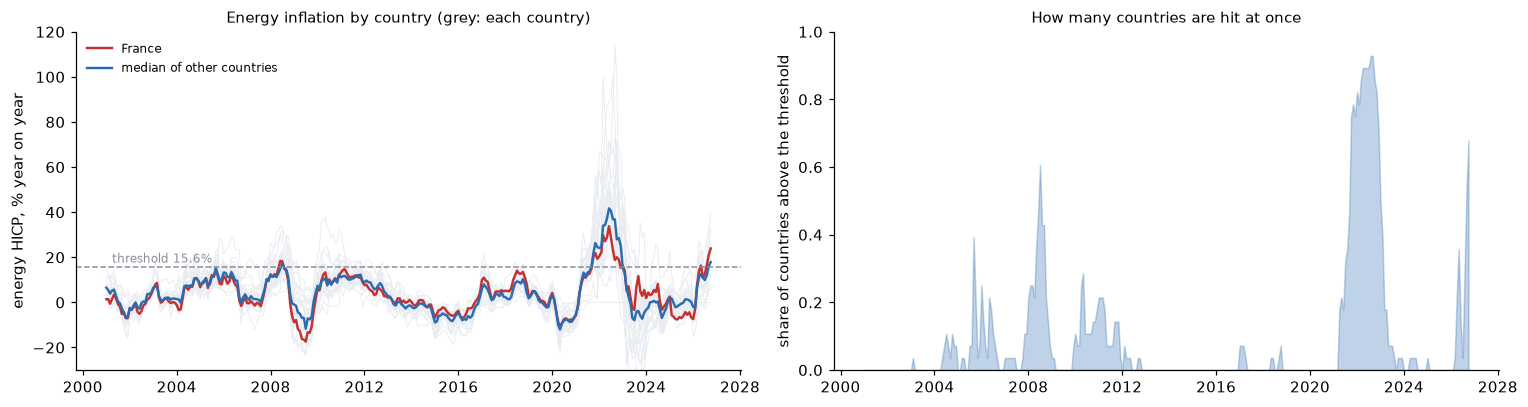

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
m = energy.pivot(index='month', columns='iso3', values='yoy')
x = m.index.to_timestamp()
ax = axes[0]
ax.plot(x, m.drop(columns=HELD_OUT), color=LIGHT, lw=0.6)
ax.plot(x, m[HELD_OUT], color=RED, lw=1.6, label='France')
ax.plot(x, m.drop(columns=HELD_OUT).median(axis=1), color=BLUE, lw=1.6, label='median of other countries')
ax.axhline(THR, color=GREY, ls='--', lw=1); ax.text(x[3], THR + 2, f'threshold {THR:.1f}%', color=GREY, fontsize=8)
ax.set_ylim(-30, 120); ax.set_ylabel('energy HICP, % year on year'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Energy inflation by country (grey: each country)', fontsize=10)
ax = axes[1]
share = (m > THR).mean(axis=1)
ax.fill_between(x, share, color=BLUE, alpha=0.3); ax.set_ylim(0, 1)
ax.set_ylabel('share of countries above the threshold'); ax.set_title('How many countries are hit at once', fontsize=10)
plt.tight_layout(); plt.show()

**Why this matters for identification.** In 2022 almost every country is above the threshold at the same time. With wave fixed effects, a wave in which *everyone* is hit has no comparison group, so the **base effect** of a spell is learned from the earlier episodes (2005, 2008, 2010–11) when only some countries were hit, and the **intensity and duration slopes** also from differences between countries within 2021–22 (the Netherlands against France, a short spell against a long one). The notebook reports how many spells stand behind each estimate.

## 2. The panel

Same as the S1 notebooks: trust and satisfaction from `data/processed/eb_panel.csv` (GESIS respondent files), one row per country and wave, a country counted only while an EU member. Controls follow the specification, plus one block added after the first version of this notebook showed that countries with the largest price rises also differed in how exposed they were:

| Control | Why |
| --- | --- |
| Country and wave fixed effects | Stable national differences; EU-wide mood in each wave (this is the "countries not hit in the same wave" comparison) |
| Unemployment, GDP growth, inflation in the **year before** the wave | Starting conditions. **Nothing measured after the shock**: if energy prices cost jobs, that is part of E's effect (specification, section 4) |
| Trust trend over the previous wave | Catches a slide already under way |
| Another cabinet ending, and a government fall (S1), in the same interval | The shocks "enter the same model, so each effect is net of the others" |
| Country under an EC/IMF bailout programme in the interval (S2) | The financial-crisis shock, so E is net of it. The 2008–09 waves are also tested **with and without** (section 9) |
| **Pre-shock exposure** of the country, measured *before* any spell it is used for: **gas as a share of gross energy supply** (2018–2020 average, Eurostat). Two further measures, the Russian share of gas imports and whether the country borders Russia, Belarus or Ukraine, are computed and tried one at a time in section 9 but are **not in the main model** (see the caution below) | This is fixed before the shock, so they are not "after the shock" controls and do not remove part of E's total effect. They separate the effect of the price rise from the effect of being a gas-dependent or front-line country (the correlation between the two is printed below) |

*Months to the next scheduled election* is not in yet (it needs constitutional term lengths per country).

In [4]:
import itertools
panel = pd.read_csv(ROOT / 'data/processed/eb_panel.csv', parse_dates=['fieldwork_median', 'fieldwork_start', 'fieldwork_end'])
panel['iso3'] = panel.country.map(iso3_of)
panel = panel.dropna(subset=['iso3'])
yr = panel.fieldwork_median.dt.year
panel = panel[(yr >= panel.iso3.map(eu_since)) & (panel.iso3.map(eu_exit).isna() | (yr < panel.iso3.map(eu_exit)))]

macro = pd.read_csv(ROOT / 'data/processed/eurostat_macro_country_year.csv')
macro['country'] = macro.geo.replace({'EL': 'GR', 'UK': 'GB'})
macro = macro.rename(columns={'nama_10_gdp_real_growth': 'growth', 'une_rt_a_unemployment': 'unemployment', 'prc_hicp_aind_inflation': 'inflation'})
panel['macro_year'] = panel.fieldwork_median.dt.year - 1
panel = panel.merge(macro[['country', 'year', 'growth', 'unemployment', 'inflation']], left_on=['country', 'macro_year'], right_on=['country', 'year'], how='left')
panel = panel.sort_values(['iso3', 'fieldwork_median']).reset_index(drop=True)

# Cabinet endings (S1 inputs) and bailout programmes (S2 inputs), as dated events per country
endings = pd.read_csv(ROOT / 'data/processed/s1_all_endings_dataset.csv', parse_dates=['event_date'])
S1_GROUPS = {'government collapse', 'collapse after a scandal', 'collapse in a financial crisis'}
endings['s1_fall'] = endings.case_group.isin(S1_GROUPS) | ((endings.case_group == 'PPEG: cabinet dissension') & (endings.s1_status == 'include'))
endings = endings[endings.case_group != 'failed government formation']

prog = pd.read_csv(ROOT / 'data/reference/s2_bailout_programmes_ec_imf.csv')
prog = prog[prog.drawn == 'yes'].assign(geo=lambda d: d.geo.replace({'EL': 'GR'}))
prog['start'] = pd.to_datetime(prog.approved)
prog['end'] = pd.to_datetime(prog.last_disbursement.astype(str).str[:7] + '-28', errors='coerce')
esm = pd.read_csv(ROOT / 'data/processed/s2_bailout_programmes.csv')
spain = esm[esm.country.str.startswith('Spain')]
bail = pd.concat([prog[['geo', 'start', 'end']],
                  pd.DataFrame({'geo': ['ES'] * len(spain), 'start': pd.to_datetime(spain.first_disbursement), 'end': pd.to_datetime(spain.last_disbursement)})])
bail = bail.dropna(subset=['start', 'end']).assign(iso3=lambda d: d.geo.map(iso3_of)).groupby('iso3').agg(start=('start', 'min'), end=('end', 'max'))
print('Bailout programme windows (S2 control):', ', '.join(f"{i} {r.start:%Y-%m} to {r.end:%Y-%m}" for i, r in bail.iterrows()))
print(f"{panel.iso3.nunique()} countries, {panel.za.nunique()} waves, {len(panel)} country-waves; estimation uses waves from {START_WAVE:%b %Y}")

# Pre-shock exposure (2018-2020 averages, before any spell used here)
def decode_all(path):
    d = json.load(open(path)); ids, sizes = d['id'], d['size']
    cats = [list(d['dimension'][k]['category']['index']) for k in ids]
    rows = []
    for pos, combo in enumerate(itertools.product(*[range(s) for s in sizes])):
        v = d['value'].get(str(pos))
        if v is not None:
            rows.append({k: cats[i][combo[i]] for i, k in enumerate(ids)} | {'value': v})
    return pd.DataFrame(rows)

PRE_YEARS = ['2018', '2019', '2020']
g = decode_all(ROOT / 'data/raw/eurostat_energy/nrg_bal_c_gas_in_gross_energy_2015_2020.json')
g = g[g.time.isin(PRE_YEARS)].pivot_table(index='geo', columns='siec', values='value', aggfunc='sum')
r_ = decode_all(ROOT / 'data/raw/eurostat_energy/nrg_ti_gas_imports_russia_2015_2020.json')
r_ = r_[r_.time.isin(PRE_YEARS)].pivot_table(index='geo', columns='partner', values='value', aggfunc='sum')
to_iso3 = lambda s: pd.Series({iso3_of[{'EL': 'GR', 'UK': 'GB'}.get(k, k)]: v for k, v in s.items() if {'EL': 'GR', 'UK': 'GB'}.get(k, k) in iso3_of})
GAS, RUS = to_iso3(g.G3000 / g.TOTAL * 100), to_iso3(r_.RU / r_.TOTAL * 100)
for c in GAS.index:
    if pd.isna(RUS.get(c, np.nan)) and GAS[c] == 0:
        RUS[c] = 0.0                                   # no gas, so no Russian gas
FRONTLINE = {'EST', 'LVA', 'LTU', 'POL', 'FIN', 'SVK', 'HUN', 'ROU'}   # land border with Russia, Belarus or Ukraine
est_countries = [c for c in panel.iso3.unique() if c != HELD_OUT and c in GAS.index and c in RUS.index]
EXPO_MEAN = {'gas': GAS[est_countries].mean(), 'rus': RUS[est_countries].mean(), 'front': float(np.mean([c in FRONTLINE for c in est_countries]))}
exposure = pd.DataFrame({'gas_share_pct': GAS, 'russian_share_of_gas_imports_pct': RUS}).reindex(sorted(panel.iso3.unique())).round(1)
exposure['frontline'] = [int(c in FRONTLINE) for c in exposure.index]
print(f"Exposure, 2018-2020 (centred on the {len(est_countries)} estimation countries: gas {EXPO_MEAN['gas']:.1f}%, Russian share {EXPO_MEAN['rus']:.1f}%, front-line {EXPO_MEAN['front']:.0%}):")
display(exposure.T)
sp21 = spells[(spells.iso3.isin(est_countries)) & (spells.start >= pd.Period('2020-06', 'M')) & ~spells.ongoing].assign(gas=lambda d: d.iso3.map(GAS), rus=lambda d: d.iso3.map(RUS), front=lambda d: d.iso3.isin(FRONTLINE).astype(float))
print(f"Correlation between a 2021-23 spell's energy rise and the country's gas share, Russian share, front-line status: {sp21.yoy.corr(sp21.gas):+.2f}, {sp21.yoy.corr(sp21.rus):+.2f}, {sp21.yoy.corr(sp21.front):+.2f} ({len(sp21)} spells)")
print('Without exposure data (their spells are dropped):', ', '.join(sorted(set(panel.iso3) - set(GAS.index) - {HELD_OUT})) or 'none')

Bailout programme windows (S2 control): CYP 2013-05 to 2016-03, ESP 2012-12 to 2013-02, GRC 2010-05 to 2016-01, HUN 2008-11 to 2010-10, IRL 2010-12 to 2014-03, LVA 2008-12 to 2011-12, PRT 2011-05 to 2014-11, ROU 2009-05 to 2011-06
28 countries, 56 waves, 1409 country-waves; estimation uses waves from Mar 2001
Exposure, 2018-2020 (centred on the 27 estimation countries: gas 20.2%, Russian share 39.3%, front-line 30%):


,AUT,BEL,BGR,CYP,CZE,DEU,DNK,ESP,EST,FIN,FRA,GBR,GRC,HRV,HUN,IRL,ITA,LTU,LUX,LVA,MLT,NLD,POL,PRT,ROU,SVK,SVN,SWE
gas_share_pct,22.1,24.5,13.6,0.0,16.7,24.5,13.8,22.1,7.5,6.3,14.8,36.1,18.2,28.0,32.1,30.8,38.7,23.5,15.3,22.2,10.0,36.2,15.6,21.7,29.1,24.0,10.7,2.1
russian_share_of_gas_imports_pct,0.0,13.8,85.1,0.0,99.7,55.9,0.0,7.1,83.0,87.6,20.5,4.9,44.3,0.0,95.0,0.0,46.3,46.6,20.0,100.0,0.0,40.6,56.9,4.3,51.4,95.9,17.2,5.3
frontline,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0


Correlation between a 2021-23 spell's energy rise and the country's gas share, Russian share, front-line status: +0.13, -0.02, -0.05 (33 spells)
Without exposure data (their spells are dropped): none


*Why one exposure.* About 60 usable spells cannot support three correlated exposure terms next to the shock terms: each one costs precision. **Gas share of supply** is the one exposure that is measured directly and reliably, so it is the single control in the main model, chosen on that ground before the later checks. The **Russian share** is rough because Eurostat records the *direct* country of origin of imports, so a country that buys Russian gas through a neighbour shows a low share (Austria and Ireland read 0%); the **front-line** indicator is a judgement. Section 9 shows the result with all three exposures, with each alone, and with none.

## 3. The model

For each outcome and each horizon *h* (the *h*-th Eurobarometer wave after the spell starts), one regression on the panel, a **local projection** (the event-study form the specification asks for):

> change in the outcome from the two waves before the spell to *h* waves after = **shock** + **shock × (energy rise − threshold)** + **shock × (months − 1)** + **shock × gas share** (centred) + later spell + other cabinet ending + government fall + bailout + trend + economy + country effects + wave effects

- The **shock** term is the base effect of a spell at the threshold that lasts one month, for a country of average exposure; the next two are the effects **per percentage point** of year-on-year energy rise and **per extra month**; the gas-share term says how the effect differs for a country that depends more on gas. A reading for **France** is the **sum** of the terms with France's own gas share, with its joint range.
- **Exact timing** (new). The baseline is the **mean of the two waves before** the spell, and the "after" wave must **start at least 30 days after the spell does**. A spell that begins less than 30 days before a wave is left out of both the events and the controls, so that no wave is counted as "after" when the price rise had barely started.
- **Which country-waves are used.** A country-wave is an **event** if a spell starts in the interval since the previous wave and there was no energy shock in the interval before. It is a **control** if there is no energy shock from the interval before it until the end of the horizon. Waves in the middle of someone's spell, or just after one, are left out, so a country is never compared with a control that is itself still reacting.
- **Placebo (h = 0).** The same regression on the change *before* the spell. It should be close to zero.
- Standard errors are clustered by country; ranges are 90%.

In [5]:
MONTH_MID = lambda p: p.to_timestamp() + pd.Timedelta(days=14)
ERA_CUT = pd.Timestamp('2020-06-01')           # spells starting from mid-2020: the 2021-23 episode
KNOT = 25.0                                     # year-on-year rise (%) where the saturating curve bends: between the typical earlier spell (mean 18%) and the 2021-23 surges (mean 32%); tried at 22 and 30 too

def month_flags(spells_df, iso3):
    # Monthly arrays for one country: is the month inside a spell, and does a spell start in it?
    idx = pd.period_range(START_MONTH, pd.Period('2026-12', 'M'), freq='M')
    inside = pd.Series(False, index=idx); starts = pd.Series(0, index=idx)
    for r in spells_df[spells_df.iso3 == iso3].itertuples():
        inside[r.start:r.end] = True; starts[r.start] = 1
    return idx, inside.to_numpy(), starts.to_numpy()

def interval_table(spells_df, iso3, t):
    # For waves with centre dates t: months inside a spell in each interval (t[j-1], t[j]], and the spell that starts in it.
    idx, inside, starts = month_flags(spells_df, iso3)
    mids = np.array([MONTH_MID(p) for p in idx], dtype='datetime64[ns]')
    t = np.asarray(t, dtype='datetime64[ns]')
    expo, start_row = np.zeros(len(t), int), np.full(len(t), -1)
    sp = spells_df[spells_df.iso3 == iso3].reset_index(drop=True)
    sp_mid = np.array([MONTH_MID(p) for p in sp.start], dtype='datetime64[ns]')
    for j in range(1, len(t)):
        sel = (mids > t[j - 1]) & (mids <= t[j])
        expo[j] = inside[sel].sum()
        cand = np.flatnonzero((sp_mid > t[j - 1]) & (sp_mid <= t[j]))
        if len(cand): start_row[j] = cand[np.argmax(sp.months.to_numpy()[cand])]
    return expo, start_row, sp

_ITAB = {}
def build_sample(outcome, h, spells_df=None, thr=None, use_s2=True, intensity='yoy', drop_waves=None, exact=True):
    # One row per usable country-wave (see section 3). h = 0 is the placebo. exact=False reproduces the first version's timing.
    spells_df = spells if spells_df is None else spells_df
    rows = []
    for iso3, d in panel[panel[outcome + '_pct'].notna()].groupby('iso3'):
        d = d.reset_index(drop=True)
        y, t = d[outcome + '_pct'].to_numpy(), d.fieldwork_median.to_numpy()
        key = (iso3, round(float(thr), 4), tuple(t))
        if key not in _ITAB:
            _ITAB[key] = interval_table(spells_df, iso3, t)
        expo, start_row, sp = _ITAB[key]
        ends = endings[endings.iso3 == iso3]
        hh = max(h, 1)
        for k in range(3 if exact else 2, len(d) - hh + 1):
            if t[k] < np.datetime64(START_WAVE):
                continue
            if drop_waves is not None and drop_waves[0] <= d.fieldwork_median[k] <= drop_waves[1]:
                continue
            lo = k - 2 if h == 0 else k - 1
            is_event = start_row[k] >= 0 and expo[lo:k].sum() == 0
            is_control = expo[lo:k + hh].sum() == 0
            if not (is_event or is_control):
                continue
            ev = sp.iloc[start_row[k]] if is_event else None
            if is_event and ev.ongoing:
                continue                                       # still running at the end of the data: its length is not known yet
            if is_event and exact:
                st = ev.start.to_timestamp()
                if not (d.fieldwork_start[k] >= st + pd.Timedelta(days=30) and d.fieldwork_end[k - 1] < st):
                    continue                                   # timing too close to a wave: neither event nor control
            gas = rus = front = 0.0
            if is_event:
                if iso3 not in GAS.index or iso3 not in RUS.index or np.isnan(GAS[iso3]) or np.isnan(RUS[iso3]):
                    continue                                   # no exposure data: the spell cannot be used
                gas, rus, front = GAS[iso3] - EXPO_MEAN['gas'], RUS[iso3] - EXPO_MEAN['rus'], float(iso3 in FRONTLINE) - EXPO_MEAN['front']
            later = float(is_event and h > 1 and (start_row[k + 1:k + h] >= 0).any())
            if intensity == 'contribution' and is_event:
                inten = (ev.yoy - thr) * (ev.weight if pd.notna(ev.weight) else np.nanmean(spells_df.weight)) / 1000
            elif intensity == 'first3' and is_event:
                inten = ev.yoy3 - thr                          # ex-ante: the rise over the first 3 months only, known 3 months in
            else:
                inten = (ev.yoy - thr) if is_event else 0.0
            mon = (ev.months - 1) if is_event else 0.0
            post = float(is_event and ev.start.to_timestamp() >= ERA_CUT)
            low = min(inten, KNOT - thr) if is_event else 0.0
            high = max(inten - (KNOT - thr), 0.0) if is_event else 0.0
            ed = ends[(ends.event_date > t[k - 1]) & (ends.event_date <= t[k])]
            bl = bail.loc[iso3] if iso3 in bail.index else None
            bailout = float(use_s2 and bl is not None and bl.start <= pd.Timestamp(t[k]) and bl.end > pd.Timestamp(t[k - 1]))
            if exact:
                base = (y[k - 2] + y[k - 3]) / 2 if h == 0 else (y[k - 1] + y[k - 2]) / 2
            else:
                base = y[k - 2] if h == 0 else y[k - 1]
            after = y[k - 1] if h == 0 else y[k + h - 1]
            rows.append({'iso3': iso3, 'wave': d.za[k], 'date': t[k], 'dy': after - base,
                         'on': float(is_event), 'intensity': inten, 'months': mon,
                         'on_gas': gas, 'on_rus': rus, 'on_front': front,
                         'int_pre': inten * (1 - post), 'int_post': inten * post, 'int_low': low, 'int_high': high,
                         'low_pre': low * (1 - post), 'low_post': low * post, 'high_post': high * post, 'mon_pre': mon * (1 - post), 'mon_post': mon * post, 'post': post,
                         'later_on': later, 'other_change': float((~ed.s1_fall).any()), 's1_fall': float(ed.s1_fall.any()),
                         'bailout': bailout, 'pre_trend': y[k - 1] - y[k - 2],
                         'growth': d.growth[k], 'unemployment': d.unemployment[k], 'inflation': d.inflation[k],
                         'spell_yoy': ev.yoy if is_event else np.nan, 'spell_months': ev.months if is_event else np.nan})
    s = pd.DataFrame(rows)
    return s.dropna(subset=['growth', 'unemployment', 'inflation']).reset_index(drop=True)

In [6]:
MAIN_SHOCK = ['on', 'intensity', 'months', 'on_gas']
ALLEXPO = ['on', 'intensity', 'months', 'on_gas', 'on_rus', 'on_front']
NOEXPO = ['on', 'intensity', 'months']
ERA_SHOCK = ['on', 'int_pre', 'int_post', 'mon_pre', 'mon_post', 'on_gas']
PW_SHOCK = ['on', 'int_low', 'int_high', 'months', 'on_gas']          # one curve that can flatten above the knot
PW_ERA = ['on', 'low_pre', 'low_post', 'high_post', 'months', 'on_gas']
CONTROLS = ['later_on', 'other_change', 's1_fall', 'bailout', 'pre_trend', 'growth', 'unemployment', 'inflation']
FOR = 'FRA'                                    # the dashboard reads the effect for France

def design(s, h=1, shock=MAIN_SHOCK):
    # 'later_on' only exists for h > 1; 'pre_trend' is the outcome itself in the placebo (h = 0)
    controls = [c for c in CONTROLS if not (c == 'pre_trend' and h == 0) and not (c == 'later_on' and h <= 1)]
    X = s[shock + controls].copy()
    X = pd.concat([X, pd.get_dummies(s.iso3, prefix='c', drop_first=True, dtype=float), pd.get_dummies(s.wave, prefix='w', drop_first=True, dtype=float)], axis=1)
    X.insert(0, 'const', 1.0)
    return X.astype(float)

def ols_cluster(y, X, groups):
    # OLS with standard errors clustered by country (CR1).
    Xv, yv = X.to_numpy(), y.to_numpy()
    XtX_inv = np.linalg.pinv(Xv.T @ Xv)
    b = XtX_inv @ Xv.T @ yv
    u = yv - Xv @ b
    meat = np.zeros((Xv.shape[1], Xv.shape[1]))
    for g_ in np.unique(groups):
        sg = Xv[groups == g_].T @ u[groups == g_]
        meat += np.outer(sg, sg)
    n, k, G = len(yv), Xv.shape[1], len(np.unique(groups))
    V = XtX_inv @ meat @ XtX_inv * G / (G - 1) * (n - 1) / (n - k)
    return pd.Series(b, X.columns), pd.DataFrame(V, X.columns, X.columns), u, G

def t90(df):
    z = 1.6448536
    return z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)

_CACHE = {}
def sample(outcome, h, **kw):
    key = (outcome, h, tuple(sorted((k, str(v)) for k, v in kw.items())))
    if key not in _CACHE:
        _CACHE[key] = build_sample(outcome, h, **({'thr': THR} | kw))
    return _CACHE[key]

def fit(outcome, h, exclude=(HELD_OUT,), shock=MAIN_SHOCK, **kw):
    s = sample(outcome, h, **kw)
    s = s[~s.iso3.isin(exclude)].reset_index(drop=True)
    X = design(s, h=h, shock=shock)
    b, V, u, G = ols_cluster(s.dy, X, s.iso3.to_numpy())
    return {'s': s, 'X': X, 'b': b, 'V': V, 'u': u, 'G': G, 'shock': shock, 'n_events': int(s.on.sum()), 'n_obs': len(s), 'events_countries': int(s[s.on == 1].iso3.nunique())}

def exposure_terms(country):
    # Centred exposure of a country; None = an average EU country (all zeros)
    if country is None:
        return {'on_gas': 0.0, 'on_rus': 0.0, 'on_front': 0.0}
    return {'on_gas': GAS[country] - EXPO_MEAN['gas'], 'on_rus': RUS[country] - EXPO_MEAN['rus'], 'on_front': float(country in FRONTLINE) - EXPO_MEAN['front']}

def reading_vec(model, yoy, months, thr=None, country=FOR, intensity_value=None):
    thr = THR if thr is None else thr
    x = pd.Series(0.0, index=model['b'].index)
    x['on'], x['intensity'] = 1, (yoy - thr) if intensity_value is None else intensity_value
    if 'months' in x.index: x['months'] = months - 1
    for k_, v_ in exposure_terms(country).items():
        if k_ in x.index: x[k_] = v_
    return x

def reading(model, yoy, months, thr=None, country=FOR, intensity_value=None):
    # t-range for a reading (used for the sensitivity tables; the main results use the bootstrap below)
    b, V = model['b'], model['V']
    x = reading_vec(model, yoy, months, thr, country, intensity_value)
    m, se = float(x @ b), float(np.sqrt(x @ V @ x))
    c = t90(model['G'] - 1)
    return m, m - c * se, m + c * se

models = {(o, h): fit(o, h) for o in OUTCOMES for h in [0] + HORIZONS}
models_sat = {(o, h): fit(o, h, shock=PW_SHOCK) for o in OUTCOMES for h in [0] + HORIZONS}      # section 9: does the shape matter?
print('Spells and country-waves behind each regression (France excluded). Old timing, for comparison, had 81 spells at h = 1:')
display(pd.DataFrame({f'h = {h}' if h else 'placebo': {OUTCOMES[o]: f"{models[(o, h)]['n_events']} spells / {models[(o, h)]['n_obs']} rows" for o in OUTCOMES} for h in [0] + HORIZONS}))

Spells and country-waves behind each regression (France excluded). Old timing, for comparison, had 81 spells at h = 1:


,placebo,h = 1,h = 2,h = 3,h = 4
Trust in government,58 spells / 934 rows,66 spells / 1016 rows,66 spells / 923 rows,66 spells / 838 rows,66 spells / 762 rows
Trust in parliament,58 spells / 921 rows,66 spells / 1003 rows,66 spells / 910 rows,66 spells / 827 rows,66 spells / 750 rows
Trust in political parties,51 spells / 829 rows,63 spells / 908 rows,63 spells / 822 rows,63 spells / 744 rows,63 spells / 674 rows
Satisfied with democracy,39 spells / 722 rows,51 spells / 788 rows,51 spells / 716 rows,51 spells / 649 rows,51 spells / 584 rows


### Ranges: wild cluster bootstrap

With only about 25 country clusters, the usual cluster-robust *t*-ranges tend to be too narrow (the first version's back-test covered 83% against a 90% target). The ranges used from here on are **wild cluster bootstrap-t** ranges: the country residuals are re-signed at random 999 times, the coefficients re-estimated and the *t*-statistic's own distribution used to set the range. It makes no assumption that the statistic is normal, and it keeps whole countries together. The *t*-ranges are still written to the output file for comparison.

In [7]:
def wild_ci(model, combos, B=999, seed=20261124, alpha=0.10):
    # Percentile-t wild cluster bootstrap (Rademacher weights, unrestricted residuals) for linear combinations C @ b of the coefficients.
    X, y, u, b = model['X'].to_numpy(), model['s'].dy.to_numpy(), model['u'], model['b'].to_numpy()
    groups = model['s'].iso3.to_numpy()
    _, inv = np.unique(groups, return_inverse=True)
    G = inv.max() + 1
    D = np.zeros((len(y), G)); D[np.arange(len(y)), inv] = 1.0
    XtXi = np.linalg.pinv(X.T @ X)
    n, k = X.shape
    adj = G / (G - 1) * (n - 1) / (n - k)
    C = np.atleast_2d(np.asarray(combos, float))
    P = C @ XtXi
    theta = C @ b
    se_of = lambda uvec: np.sqrt(adj * ((D.T @ (X * uvec[:, None]) @ P.T) ** 2).sum(axis=0))
    se0 = se_of(u)
    rng = np.random.default_rng(seed)
    fitted = X @ b
    T = np.empty((B, len(C)))
    for i in range(B):
        ys = fitted + rng.choice([-1.0, 1.0], size=G)[inv] * u
        bs = XtXi @ (X.T @ ys)
        T[i] = (C @ bs - theta) / se_of(ys - X @ bs)
    qlo, qhi = np.nanquantile(T, [alpha / 2, 1 - alpha / 2], axis=0)
    return theta, theta - qhi * se0, theta - qlo * se0

_BR, _BT = {}, {}
def reading_b(o, h, yoy, months, country=FOR):
    key = (o, h, yoy, months, country)
    if key not in _BR:
        mdl = models[(o, h)]
        th, lo, hi = wild_ci(mdl, reading_vec(mdl, yoy, months, country=country).to_numpy())
        _BR[key] = (float(th[0]), float(lo[0]), float(hi[0]))
    return _BR[key]

def term_cis(o, h):
    # Bootstrap range of each shock term of one model
    if (o, h) not in _BT:
        mdl = models[(o, h)]
        idx = list(mdl['b'].index)
        C = np.zeros((len(mdl['shock']), len(idx)))
        for i, t_ in enumerate(mdl['shock']): C[i, idx.index(t_)] = 1.0
        th, lo, hi = wild_ci(mdl, C)
        _BT[(o, h)] = {t_: (float(th[i]), float(lo[i]), float(hi[i])) for i, t_ in enumerate(mdl['shock'])}
    return _BT[(o, h)]

import time; _t0 = time.time()
for o in OUTCOMES:
    for h in [0] + HORIZONS:
        reading_b(o, h, EXAMPLE['yoy'], EXAMPLE['months']); term_cis(o, h)
print(f'bootstrap done in {time.time() - _t0:.0f} s')
w_t = [reading(models[(o, 2)], EXAMPLE['yoy'], EXAMPLE['months']) for o in OUTCOMES]; w_b = [reading_b(o, 2, EXAMPLE['yoy'], EXAMPLE['months']) for o in OUTCOMES]
print('Width of the 90% range at h = 2, t-range vs bootstrap:', ', '.join(f"{OUTCOMES[o]} {a[2] - a[1]:.1f} vs {b_[2] - b_[1]:.1f}" for o, a, b_ in zip(OUTCOMES, w_t, w_b)))

bootstrap done in 4 s
Width of the 90% range at h = 2, t-range vs bootstrap: Trust in government 10.4 vs 12.3, Trust in parliament 6.9 vs 8.4, Trust in political parties 7.8 vs 10.1, Satisfied with democracy 7.3 vs 6.9


## 4. The specification's example: +35% year on year for 6 months

The reading the dashboard would show for the example in the specification, **for France** (using France's own gas exposure), at each horizon, with the placebo first. It is the **sum** of the base effect, the intensity term (35% minus the threshold), the duration term (5 months beyond the first) and the exposure terms. The second table is the same reading for an average EU country.

FRANCE: +35% year on year for 6 months, points, 90% wild-bootstrap range, estimated without France (gas 15% of supply, Russian share 21%, not front-line):


,placebo (before),h = 1,h = 2,h = 3,h = 4
Outcome,,,,,
Trust in government,+0.7 (-10.9 to +12.8),-0.2 (-3.7 to +3.3),-6.6 (-12.5 to -0.2),-2.4 (-7.9 to +3.1),-1.8 (-8.7 to +4.7)
Trust in parliament,+0.9 (-10.5 to +12.9),+0.5 (-3.3 to +4.1),-6.9 (-11.2 to -2.8),-3.0 (-7.4 to +1.3),-3.1 (-9.9 to +3.4)
Trust in political parties,-3.4 (-14.3 to +7.6),-0.7 (-2.3 to +0.8),-5.3 (-10.3 to -0.1),-3.0 (-7.2 to +1.2),+0.5 (-2.7 to +3.6)
Satisfied with democracy,-2.3 (-9.1 to +4.1),+0.6 (-3.1 to +4.5),-4.0 (-7.4 to -0.5),+2.8 (-0.8 to +6.5),+4.8 (-5.0 to +14.2)


Average EU country, same shock:


,placebo (before),h = 1,h = 2,h = 3,h = 4
Outcome,,,,,
Trust in government,-0.2 (-12.7 to +12.5),-0.8 (-4.1 to +2.7),-6.7 (-12.3 to -1.0),-3.3 (-8.0 to +1.3),-1.5 (-8.8 to +5.3)
Trust in parliament,+0.3 (-12.7 to +13.5),-0.1 (-4.1 to +3.8),-7.0 (-11.3 to -2.8),-4.0 (-7.9 to -0.3),-2.7 (-9.8 to +4.1)
Trust in political parties,-3.9 (-15.4 to +7.7),-1.2 (-3.0 to +0.5),-5.4 (-10.3 to -0.1),-2.7 (-6.6 to +1.1),+0.4 (-2.4 to +3.3)
Satisfied with democracy,-3.1 (-9.3 to +2.7),+0.3 (-2.5 to +3.2),-4.2 (-6.9 to -1.5),+1.4 (-2.0 to +4.8),+3.4 (-6.1 to +12.7)


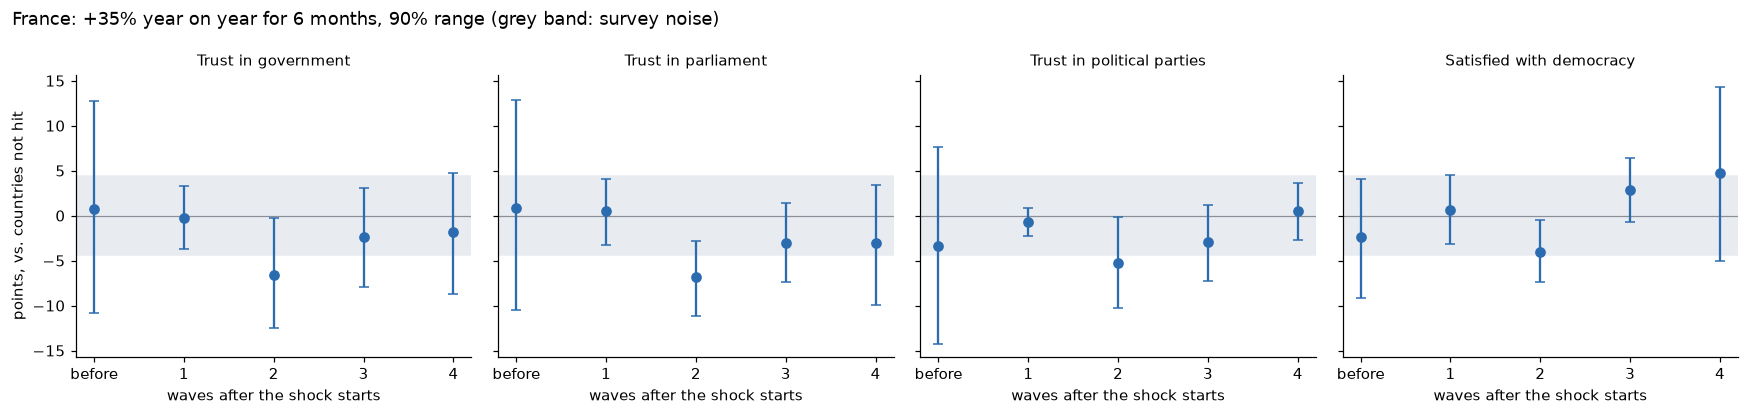

In [8]:
def example_table(country):
    rows = []
    for o, label in OUTCOMES.items():
        row = {'Outcome': label}
        for h in [0] + HORIZONS:
            m, lo, hi = reading_b(o, h, EXAMPLE['yoy'], EXAMPLE['months'], country)
            row['placebo (before)' if h == 0 else f'h = {h}'] = f"{m:+.1f} ({lo:+.1f} to {hi:+.1f})"
        rows.append(row)
    return pd.DataFrame(rows).set_index('Outcome')

print(f"FRANCE: +{EXAMPLE['yoy']:.0f}% year on year for {EXAMPLE['months']} months, points, 90% wild-bootstrap range, estimated without France (gas {GAS[FOR]:.0f}% of supply, Russian share {RUS[FOR]:.0f}%, not front-line):")
example_tab = example_table(FOR); display(example_tab)
print('Average EU country, same shock:'); display(example_table(None))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (o, label) in zip(axes, OUTCOMES.items()):
    r = np.array([reading_b(o, h, EXAMPLE['yoy'], EXAMPLE['months']) for h in [0] + HORIZONS])
    ax.axhspan(-NOISE, NOISE, color=LIGHT, zorder=0); ax.axhline(0, color=GREY, lw=0.8)
    ax.errorbar([0] + HORIZONS, r[:, 0], yerr=[r[:, 0] - r[:, 1], r[:, 2] - r[:, 0]], fmt='o', color=BLUE, capsize=3)
    ax.set_xticks([0] + HORIZONS, ['before'] + [str(h) for h in HORIZONS]); ax.set_title(label, fontsize=10); ax.set_xlabel('waves after the shock starts')
axes[0].set_ylabel('points, vs. countries not hit')
fig.suptitle(f"France: +{EXAMPLE['yoy']:.0f}% year on year for {EXAMPLE['months']} months, 90% range (grey band: survey noise)", x=0.01, ha='left')
plt.tight_layout(); plt.show()

## 5. Effect per unit of each slider

The table the dashboard reads: the effect of **one more percentage point** of energy inflation and of **one more month** of duration, plus the base effect and the exposure terms. Shown for the first and second wave after the shock starts.

In [9]:
LABEL = {'on': 'A spell at the threshold, 1 month (base effect)', 'intensity': 'Per +1 point of year-on-year energy rise',
         'months': 'Per extra month of duration', 'on_gas': 'Per +1 point of gas share of supply (exposure)',
         'on_rus': 'Per +1 point of Russian share of gas imports (exposure)', 'on_front': 'Front-line country (exposure)',
         'later_on': 'Control: a later spell inside the horizon', 'bailout': 'Control: bailout programme (S2)',
         'other_change': 'Control: other cabinet ending', 's1_fall': 'Control: government fall (S1)'}
c90 = lambda mdl: t90(mdl['G'] - 1)
cell = lambda mdl, t: f"{mdl['b'][t]:+.2f} ({mdl['b'][t] - c90(mdl) * np.sqrt(mdl['V'].loc[t, t]):+.2f} to {mdl['b'][t] + c90(mdl) * np.sqrt(mdl['V'].loc[t, t]):+.2f})"
def cellb(o, h, t):
    # bootstrap range for the shock terms; t-range for the controls
    if t in term_cis(o, h):
        m_, lo_, hi_ = term_cis(o, h)[t]
        return f"{m_:+.2f} ({lo_:+.2f} to {hi_:+.2f})"
    return cell(models[(o, h)], t)
for h in [1, 2]:
    print(f'h = {h} ({"first" if h == 1 else "second"} wave after), points, 90% range (bootstrap for the shock terms, t-range for the controls):')
    display(pd.DataFrame({OUTCOMES[o]: {LABEL[t]: (cellb(o, h, t) if t in models[(o, h)]['b'].index else 'n/a') for t in LABEL if t in models[(o, 2)]['b'].index} for o in OUTCOMES}))

h = 1 (first wave after), points, 90% range (bootstrap for the shock terms, t-range for the controls):


,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
"A spell at the threshold, 1 month (base effect)",+0.13 (-2.24 to +2.53),-0.01 (-1.58 to +1.54),-0.34 (-2.33 to +1.62),+0.09 (-2.07 to +2.41)
Per +1 point of year-on-year energy rise,+0.03 (-0.15 to +0.21),+0.08 (-0.15 to +0.30),-0.03 (-0.13 to +0.06),+0.05 (-0.12 to +0.24)
Per extra month of duration,-0.30 (-0.54 to -0.04),-0.33 (-0.49 to -0.17),-0.04 (-0.27 to +0.18),-0.17 (-0.52 to +0.14)
Per +1 point of gas share of supply (exposure),-0.11 (-0.21 to -0.01),-0.11 (-0.18 to -0.04),-0.09 (-0.21 to +0.03),-0.06 (-0.27 to +0.12)
Control: a later spell inside the horizon,n/a,n/a,n/a,n/a
Control: bailout programme (S2),-0.18 (-2.58 to +2.22),-0.37 (-2.45 to +1.71),+0.08 (-0.85 to +1.02),-1.16 (-2.66 to +0.35)
Control: other cabinet ending,+0.22 (-1.19 to +1.64),-0.28 (-1.06 to +0.50),-0.77 (-1.64 to +0.09),-0.01 (-1.34 to +1.32)
Control: government fall (S1),+1.32 (-1.86 to +4.50),+0.64 (-2.47 to +3.75),+0.16 (-1.71 to +2.03),+0.65 (-1.69 to +2.98)


h = 2 (second wave after), points, 90% range (bootstrap for the shock terms, t-range for the controls):


,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
"A spell at the threshold, 1 month (base effect)",+0.97 (-2.47 to +4.29),+1.10 (-1.27 to +3.32),+0.64 (-1.59 to +2.79),+3.04 (+0.37 to +5.81)
Per +1 point of year-on-year energy rise,-0.33 (-0.64 to -0.03),-0.36 (-0.60 to -0.12),-0.30 (-0.56 to -0.07),-0.36 (-0.53 to -0.19)
Per extra month of duration,-0.26 (-0.84 to +0.27),-0.24 (-0.55 to +0.04),-0.03 (-0.20 to +0.14),-0.04 (-0.55 to +0.44)
Per +1 point of gas share of supply (exposure),-0.03 (-0.22 to +0.15),-0.03 (-0.12 to +0.07),-0.02 (-0.12 to +0.08),-0.03 (-0.28 to +0.19)
Control: a later spell inside the horizon,+0.98 (-2.11 to +4.08),-2.82 (-5.98 to +0.34),-2.55 (-6.14 to +1.04),-11.91 (-17.85 to -5.97)
Control: bailout programme (S2),-1.35 (-3.15 to +0.45),-1.12 (-3.06 to +0.82),+0.27 (-0.95 to +1.49),-1.24 (-3.43 to +0.96)
Control: other cabinet ending,-0.74 (-2.56 to +1.09),-1.07 (-2.15 to +0.02),-1.16 (-2.42 to +0.10),-0.31 (-1.77 to +1.16)
Control: government fall (S1),+3.03 (-0.57 to +6.63),+1.78 (-1.49 to +5.06),+0.74 (-0.93 to +2.40),+0.58 (-2.35 to +3.52)


### Dose-response

The reading for France across each slider, holding the other at the specification's example (35% for 6 months), second wave after. Ticks on the axis are the observed spells: **the sliders stop at the largest spell seen**, so the reading never goes beyond what the data have seen.

Slider limits from the 99 estimation spells: energy rise 15.6% to 60% (largest spell mean; the single largest month is 114%), duration 1 to 29 months
Largest spell means: NLD 2021-08 (60%), EST 2021-06 (49%), BEL 2021-04 (47%)


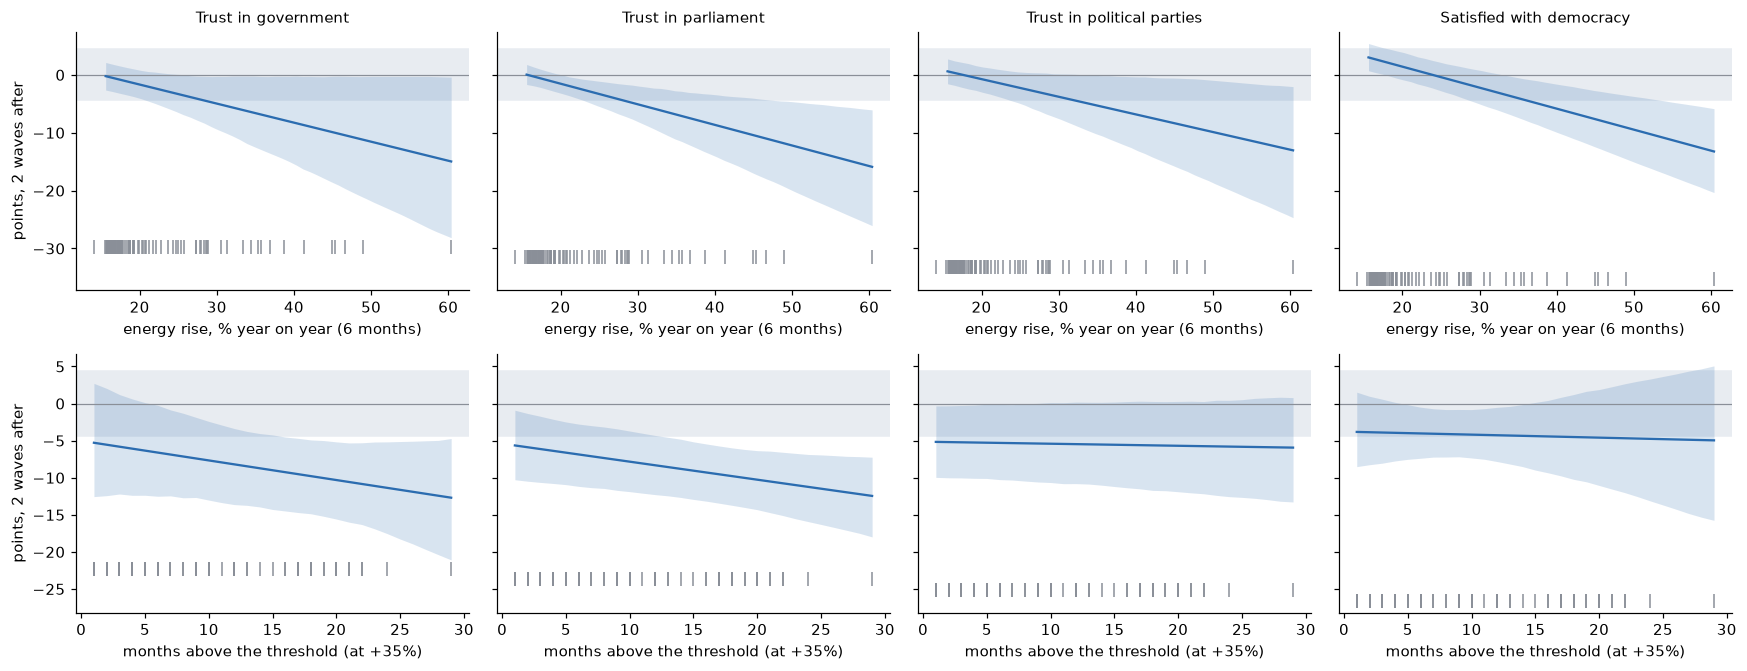

In [10]:
sp_est = spells[(spells.iso3 != HELD_OUT) & ~spells.ongoing]
YOY_MAX, MONTHS_MAX = float(sp_est.yoy.max()), int(sp_est.months.max())
print(f"Slider limits from the {len(sp_est)} estimation spells: energy rise {THR:.1f}% to {YOY_MAX:.0f}% (largest spell mean; the single largest month is {energy[(energy.iso3 != HELD_OUT) & (energy.month <= PRE_2026)].yoy.max():.0f}%), duration 1 to {MONTHS_MAX} months")
print('Largest spell means:', ', '.join(f"{r.iso3} {r.start} ({r.yoy:.0f}%)" for r in sp_est.nlargest(3, 'yoy').itertuples()))
fig, axes = plt.subplots(2, 4, figsize=(16, 6.2), sharey='row')
for j, (o, label) in enumerate(OUTCOMES.items()):
    for i, (xs, kind) in enumerate([(np.linspace(THR, YOY_MAX, 50), 'yoy'), (np.arange(1, MONTHS_MAX + 1), 'months')]):
        ax = axes[i, j]
        combos = np.array([reading_vec(models[(o, 2)], x if kind == 'yoy' else EXAMPLE['yoy'], EXAMPLE['months'] if kind == 'yoy' else x).to_numpy() for x in xs])
        th_, lo_, hi_ = wild_ci(models[(o, 2)], combos)
        r = np.column_stack([th_, lo_, hi_])
        ax.axhspan(-NOISE, NOISE, color=LIGHT, zorder=0); ax.axhline(0, color=GREY, lw=0.8)
        ax.fill_between(xs, r[:, 1], r[:, 2], color=BLUE, alpha=0.18, lw=0); ax.plot(xs, r[:, 0], color=BLUE)
        obs = sp_est.yoy if kind == 'yoy' else sp_est.months
        ax.plot(obs, np.full(len(obs), ax.get_ylim()[0]), '|', color=GREY, ms=9)
        if i == 0: ax.set_title(label, fontsize=10)
        ax.set_xlabel('energy rise, % year on year (6 months)' if kind == 'yoy' else 'months above the threshold (at +35%)')
    axes[0, 0].set_ylabel('points, 2 waves after'); axes[1, 0].set_ylabel('points, 2 waves after')
plt.tight_layout(); plt.show()

## 6. Reliability

How many spells stand behind each estimate, whether the example reading for France can be told apart from zero and from survey noise, and whether the placebo is clean. The **slope** columns say whether intensity and duration carry any signal on their own.

In [11]:
rel = []
for o, label in OUTCOMES.items():
    pm = models[(o, 0)]
    pl = reading_b(o, 0, EXAMPLE['yoy'], EXAMPLE['months'])
    for h in HORIZONS:
        mdl = models[(o, h)]
        m, lo, hi = reading_b(o, h, EXAMPLE['yoy'], EXAMPLE['months'])
        verdict = ('range excludes zero' + ('' if abs(m) > NOISE else ', but smaller than survey noise')) if (lo > 0 or hi < 0) else 'no detectable change'
        rel.append({'Outcome': label, 'h': h, 'Spells': mdl['n_events'], 'Countries': mdl['events_countries'], 'Rows': mdl['n_obs'],
                    'France, example': f"{m:+.1f} ({lo:+.1f} to {hi:+.1f})", 'Reading': verdict,
                    'Per +1 pt': cellb(o, h, 'intensity'), 'Per month': cellb(o, h, 'months'),
                    'Placebo clean?': 'yes' if pl[1] <= 0 <= pl[2] else f'no ({pl[0]:+.1f})'})
rel = pd.DataFrame(rel)
display(rel)

,Outcome,h,Spells,Countries,Rows,"France, example",Reading,Per +1 pt,Per month,Placebo clean?
0,Trust in government,1,66,25,1016,-0.2 (-3.7 to +3.3),no detectable change,+0.03 (-0.15 to +0.21),-0.30 (-0.54 to -0.04),yes
1,Trust in government,2,66,25,923,-6.6 (-12.5 to -0.2),range excludes zero,-0.33 (-0.64 to -0.03),-0.26 (-0.84 to +0.27),yes
2,Trust in government,3,66,25,838,-2.4 (-7.9 to +3.1),no detectable change,-0.08 (-0.36 to +0.22),-0.65 (-1.36 to +0.01),yes
3,Trust in government,4,66,25,762,-1.8 (-8.7 to +4.7),no detectable change,-0.13 (-0.65 to +0.36),-0.65 (-0.98 to -0.33),yes
4,Trust in parliament,1,66,25,1003,+0.5 (-3.3 to +4.1),no detectable change,+0.08 (-0.15 to +0.30),-0.33 (-0.49 to -0.17),yes
5,Trust in parliament,2,66,25,910,-6.9 (-11.2 to -2.8),range excludes zero,-0.36 (-0.60 to -0.12),-0.24 (-0.55 to +0.04),yes
6,Trust in parliament,3,66,25,827,-3.0 (-7.4 to +1.3),no detectable change,-0.08 (-0.35 to +0.17),-0.67 (-1.00 to -0.37),yes
7,Trust in parliament,4,66,25,750,-3.1 (-9.9 to +3.4),no detectable change,-0.13 (-0.60 to +0.32),-0.78 (-1.06 to -0.51),yes
8,Trust in political parties,1,63,25,908,-0.7 (-2.3 to +0.8),no detectable change,-0.03 (-0.13 to +0.06),-0.04 (-0.27 to +0.18),yes
9,Trust in political parties,2,63,25,822,-5.3 (-10.3 to -0.1),range excludes zero,-0.30 (-0.56 to -0.07),-0.03 (-0.20 to +0.14),yes


## 7. Check on France, out of sample

The model above never saw France. Here it predicts France's own spell, and the prediction is compared with what happened.

- **France 2021–23:** the long spell of energy inflation above the threshold (its dates, intensity and duration are printed below), with the regulated-price cap (*bouclier tarifaire*) in force.
- Spells of 3 months or less (France has one in 2008, just before the financial crisis) are not used as checks: too short to read, and 2008 overlaps S2.

**Predicted** = the effect of a spell with France's own intensity, duration and exposure, with a 90% range for *one* episode (model uncertainty plus the spread of individual episodes). **Actual** = France's change minus what the model attributes to everything else (wave effect, economy, trend): the part a spell would have to explain.

In [12]:
def predict_rows(model_o, rows_all):
    # Predicted and 'actual' shock effect for event rows of a country the model did not see.
    b, V, u, G, shock = model_o['b'], model_o['V'], model_o['u'], model_o['G'], model_o['shock']
    cols = list(b.index)
    cfe = [c for c in cols if c.startswith('c_')]
    sigma = np.sqrt(np.sum(u ** 2) / (len(u) - len(cols)))
    out = []
    for i, r in rows_all.iterrows():
        x = pd.Series(0.0, index=cols)
        x['const'] = 1.0
        for c in CONTROLS:
            if c in x.index: x[c] = r[c]
        if f"w_{r.wave}" in x.index: x[f"w_{r.wave}"] = 1.0
        other = float(x @ b) + b[cfe].sum() / (len(cfe) + 1)      # everything except the shock, for an average country
        xs = pd.Series(0.0, index=cols)
        for t_ in shock: xs[t_] = 1.0 if t_ == 'on' else r[t_]
        m, se = float(xs @ b), float(np.sqrt(xs @ V @ xs))
        half = t90(G - 1) * np.sqrt(se ** 2 + sigma ** 2)
        out.append({'predicted': m, 'pred_low': m - half, 'pred_high': m + half, 'actual': r.dy - other, 'observed_change': r.dy})
    return pd.DataFrame(out, index=rows_all.index)

print(spells[spells.iso3 == HELD_OUT].assign(start=lambda d: d.start.astype(str), end=lambda d: d.end.astype(str)).round(1).to_string(index=False))
fc = []
for o in OUTCOMES:
    for h in HORIZONS:
        full = sample(o, h)
        fr = full[(full.iso3 == HELD_OUT) & (full.on == 1) & (full.spell_months > 3)]
        if fr.empty: continue
        p = predict_rows(models[(o, h)], fr)
        fc.append(pd.concat([fr[['iso3', 'date', 'spell_yoy', 'spell_months']].reset_index(drop=True), p.reset_index(drop=True)], axis=1).assign(outcome=o, horizon=h))
france_check = pd.concat(fc).assign(scenario='E', episode='France 2021-23')
france_check['inside'] = france_check.actual.between(france_check.pred_low, france_check.pred_high)
show = france_check.assign(Outcome=france_check.outcome.map(OUTCOMES), Predicted=lambda d: d.apply(lambda r: f"{r.predicted:+.1f} ({r.pred_low:+.1f} to {r.pred_high:+.1f})", axis=1),
                           Actual=lambda d: d.actual.round(1), **{'Raw change': france_check.observed_change.round(1)})
display(show[['Outcome', 'horizon', 'Predicted', 'Actual', 'Raw change', 'inside']].reset_index(drop=True))

iso3   start     end  months  yoy  peak  yoy3  ongoing  weight
 FRA 2008-06 2008-07       2 18.3  18.4  18.3    False    87.5
 FRA 2021-10 2023-01      16 22.8  33.8  20.5    False    85.9
 FRA 2026-05 2026-10       6 16.9  23.9  13.3     True    93.2


,Outcome,horizon,Predicted,Actual,Raw change,inside
0,Trust in government,1,-3.5 (-14.5 to +7.4),-2.2,-1.9,True
1,Trust in government,2,-5.2 (-18.1 to +7.6),-11.9,-5.6,True
2,Trust in government,3,-8.0 (-22.7 to +6.7),-12.0,-5.6,True
3,Trust in government,4,-6.7 (-21.7 to +8.3),-10.4,-8.2,True
4,Trust in parliament,1,-3.8 (-13.1 to +5.5),-3.9,-2.0,True
5,Trust in parliament,2,-5.0 (-15.4 to +5.5),-10.7,-2.6,True
6,Trust in parliament,3,-8.8 (-20.6 to +3.1),-16.1,-5.8,True
7,Trust in parliament,4,-9.3 (-21.5 to +2.9),-14.8,-6.6,True
8,Trust in political parties,1,-0.8 (-8.3 to +6.8),-3.7,-2.6,True
9,Trust in political parties,2,-1.9 (-10.2 to +6.4),-6.9,0.3,True


## 8. Back-test: leave one country out, scored against "no change"

For every country with a spell, the model is estimated **without that country** and asked to predict each of its spells. Two scores:

- **Coverage:** how many real outcomes fall inside the 90% range (target about 9 in 10). **This alone proves little**: a range wide enough is always right.
- **Skill against "no change":** the mean absolute error of the model's prediction against the error of simply predicting zero. If the model is not lower, it adds nothing beyond saying the shock does nothing. Also the correlation between predicted and actual.

In [13]:
bt = []
countries = sorted(spells.loc[spells.iso3 != HELD_OUT, 'iso3'].unique())
for o in OUTCOMES:
    for h in HORIZONS:
        full = sample(o, h)
        ev_all = full[(full.on == 1) & (full.iso3 != HELD_OUT)]
        for iso3 in countries:
            rows_c = ev_all[ev_all.iso3 == iso3]
            if rows_c.empty: continue
            mdl = fit(o, h, exclude=(HELD_OUT, iso3))
            p = predict_rows(mdl, rows_c)
            bt.append(pd.concat([rows_c[['iso3', 'date', 'spell_yoy', 'spell_months']], p], axis=1).assign(scenario='E', outcome=o, horizon=h))
backtest = pd.concat(bt).reset_index(drop=True)
backtest['inside'] = backtest.actual.between(backtest.pred_low, backtest.pred_high)
backtest['err_model'] = (backtest.actual - backtest.predicted).abs()
backtest['err_zero'] = backtest.actual.abs()
skill = backtest.groupby(['outcome', 'horizon']).apply(lambda g_: pd.Series({
    'spells': len(g_), 'coverage': g_.inside.mean(), 'mean width': (g_.pred_high - g_.pred_low).mean(),
    'MAE model': g_.err_model.mean(), 'MAE "no change"': g_.err_zero.mean(),
    'model beats no-change': g_.err_model.mean() < g_.err_zero.mean(), 'corr(pred, actual)': g_.predicted.corr(g_.actual)}), include_groups=False).round(2)
skill.index = pd.MultiIndex.from_tuples([(OUTCOMES[o], h) for o, h in skill.index], names=['outcome', 'h'])
display(skill)
print(f"Overall: coverage {backtest.inside.mean():.2f} (target 0.90); model beats 'no change' in {int(skill['model beats no-change'].sum())} of {len(skill)} outcome-horizon cells.")

spells  coverage  mean width  MAE model  MAE "no change"  model beats no-change  corr(pred, actual)
outcome                    h                                                                                                     
Satisfied with democracy   1      51      0.88       18.34       5.00             4.63                  False               -0.26
                           2      51      0.82       22.51       6.86             7.14                   True                0.29
                           3      51      0.78       25.95       8.81             8.47                  False                0.09
                           4      51      0.78       29.53      10.94            10.11                  False               -0.16
Trust in government        1      66      0.85       22.18       5.58             5.96                   True                0.19
                           2      66      0.86       26.21       7.17             8.10                   True                0.36
                           3      66      0.83       29.37       9.11            10.34                   True                0.33
                           4      66      0.80       30.52       9.65            10.48                   True                0.36
Trust in parliament        1      66      0.85       18.77       4.96             5.18                   True                0.20
                           2      66      0.86       21.22       5.29             6.58                   True                0.50
                           3      66      0.74       23.93       7.82             9.45                   True                0.40
                           4      66      0.79       24.66       8.29             9.63                   True                0.49
Trust in political parties 1      63      0.84       15.36       4.32             4.10                  False               -0.02
                           2      63      0.83       16.98       4.52             5.12                   True                0.31
                           3      63      0.84       17.71       4.94             5.71                   True                0.35
                           4      63      0.79       18.79       6.06             6.02                  False                0.19

Overall: coverage 0.82 (target 0.90); model beats 'no change' in 11 of 16 outcome-horizon cells.


### Calibrated prediction ranges (conformal)

The model-based ranges for a single episode did not cover 90% of outcomes. A **conformal** range fixes that without assuming a distribution: it takes the model's prediction and adds the error size that 90% of *other countries'* past episodes stayed within. Scored fairly: for each country the half-width is computed **from the other countries only**, then checked on that country's spells. The half-width on all spells is what the dashboard should add around a reading to speak about *one* future episode.

In [14]:
def conformal_q(scores, level=0.90):
    n = len(scores)
    return np.sort(scores)[min(n, int(np.ceil((n + 1) * level))) - 1]

crows = []
for (o, h), g_ in backtest.groupby(['outcome', 'horizon']):
    inside = []
    for c in g_.iso3.unique():
        q_c = conformal_q(g_[g_.iso3 != c].err_model.to_numpy())
        inside += list((g_[g_.iso3 == c].err_model <= q_c))
    q_all = conformal_q(g_.err_model.to_numpy())
    crows.append({'outcome': o, 'horizon': h, 'spells': len(g_), 'model coverage': g_.inside.mean(), 'model width': (g_.pred_high - g_.pred_low).mean(),
                  'conformal coverage': float(np.mean(inside)), 'conformal width': 2 * q_all, 'conformal_half_width': q_all})
conf = pd.DataFrame(crows)
show_c = conf.assign(outcome=conf.outcome.map(OUTCOMES)).set_index(['outcome', 'horizon']).drop(columns='conformal_half_width').round(2)
display(show_c)
print(f"Coverage of single-episode ranges (target 0.90): model-based {conf['model coverage'].mean():.2f}, conformal {conf['conformal coverage'].mean():.2f}; mean width {conf['model width'].mean():.1f} vs {conf['conformal width'].mean():.1f} points")
france_check = france_check.merge(conf[['outcome', 'horizon', 'conformal_half_width']], on=['outcome', 'horizon'], how='left')
france_check['inside_conformal'] = (france_check.actual - france_check.predicted).abs() <= france_check.conformal_half_width
print(f"France 2021-23: {int(france_check.inside_conformal.sum())} of {len(france_check)} readings inside the conformal range (model-based: {int(france_check.inside.sum())} of {len(france_check)})")

spells  model coverage  model width  conformal coverage  conformal width
outcome                    horizon                                                                          
Satisfied with democracy   1            51            0.88        18.34                0.90            19.17
                           2            51            0.82        22.51                0.92            28.32
                           3            51            0.78        25.95                0.90            32.15
                           4            51            0.78        29.53                0.90            42.86
Trust in government        1            66            0.85        22.18                0.89            25.08
                           2            66            0.86        26.21                0.91            29.89
                           3            66            0.83        29.37                0.91            40.13
                           4            66            0.80        30.52                0.91            37.49
Trust in parliament        1            66            0.85        18.77                0.89            23.18
                           2            66            0.86        21.22                0.89            26.12
                           3            66            0.74        23.93                0.89            32.93
                           4            66            0.79        24.66                0.89            32.21
Trust in political parties 1            63            0.84        15.36                0.90            20.83
                           2            63            0.83        16.98                0.92            23.24
                           3            63            0.84        17.71                0.89            24.18
                           4            63            0.79        18.79                0.92            23.51

Coverage of single-episode ranges (target 0.90): model-based 0.82, conformal 0.90; mean width 22.6 vs 28.8 points
France 2021-23: 16 of 16 readings inside the conformal range (model-based: 16 of 16)


### Forward in time: does the pre-2020 pattern predict 2021–23?

The leave-one-country-out back-test mixes eras. This one respects time: the model is estimated **only on spells and controls before mid-2020**, then asked about the 2021–23 spells. Because every wave of 2021–22 has its own EU-wide mood that cannot be learned from earlier waves, the test is **within each wave**: do the countries the model expects to lose more trust actually lose more, compared with the wave's average? It is scored against a model that says all countries react alike. (The level of the reaction cannot be tested this way, only the pattern across countries.)

In [15]:
CUT = np.datetime64('2020-06-01')
rows = []
for o in OUTCOMES:
    for h in HORIZONS:
        full = sample(o, h); full = full[full.iso3 != HELD_OUT].reset_index(drop=True)
        train = full[full.date < CUT].reset_index(drop=True)
        b, V, u, G = ols_cluster(train.dy, design(train, h=h), train.iso3.to_numpy())
        test = full[(full.date >= CUT) & (full.on == 1)].copy()
        test = test[test.wave.map(test.wave.value_counts()) >= 3]
        ctrl = sum(b[c] * test[c] for c in CONTROLS if c in b.index)
        shock_ = sum(b[t] * test[t] for t in MAIN_SHOCK)
        within = lambda s_: s_ - s_.groupby(test.wave).transform('mean')
        obs, pred = within(test.dy - ctrl), within(shock_)
        rows.append({'Outcome': OUTCOMES[o], 'h': h, 'test spells': len(test), 'within-wave MAE, model': (obs - pred).abs().mean(),
                     'within-wave MAE, all alike': obs.abs().mean(), 'corr(pred, actual)': obs.corr(pred), 'actual per predicted': float((obs * pred).sum() / (pred ** 2).sum())})
fwd = pd.DataFrame(rows)
fwd['beats'] = fwd['within-wave MAE, model'] < fwd['within-wave MAE, all alike']
display(fwd.set_index(['Outcome', 'h']).round(2))
print(f"The pre-2020 model beats 'all countries alike' in {int(fwd.beats.sum())} of {len(fwd)} cells; correlation between predicted and actual pattern: median {fwd['corr(pred, actual)'].median():.2f}; actual effects are about {fwd['actual per predicted'].median():.2f} times the predicted ones (median).")

test spells  within-wave MAE, model  within-wave MAE, all alike  corr(pred, actual)  actual per predicted  beats
Outcome                    h                                                                                                                  
Trust in government        1           16                    5.70                        3.03                0.45                  0.28  False
                           2           16                    8.78                        4.03                0.44                  0.21  False
                           3           16                   13.45                        4.21                0.33                  0.10  False
                           4           16                    8.58                        5.02                0.46                  0.24  False
Trust in parliament        1           16                    5.34                        2.63                0.45                  0.20  False
                           2           16                    6.69                        3.78                0.73                  0.34  False
                           3           16                   11.12                        4.48                0.42                  0.18  False
                           4           16                    6.92                        4.63                0.56                  0.34  False
Trust in political parties 1           16                    4.46                        2.73                0.22                  0.15  False
                           2           16                    4.31                        3.25                0.68                  0.38  False
                           3           16                    5.97                        3.12                0.23                  0.12  False
                           4           16                    5.62                        3.55                0.16                  0.10  False
Satisfied with democracy   1           16                    3.05                        2.93                0.25                  0.37  False
                           2           16                    5.90                        6.13                0.67                  0.48   True
                           3           16                    8.27                        6.54                0.31                  0.29  False
                           4           16                    7.15                        6.74               -0.17                 -0.59  False

The pre-2020 model beats 'all countries alike' in 1 of 16 cells; correlation between predicted and actual pattern: median 0.43; actual effects are about 0.22 times the predicted ones (median).


### Can the dashboard use an ex-ante input?

The spell's **mean rise and length** are only known when a surge ends. A forecast needs something known *during* it. This re-estimates the model with **only the rise over the first three months** (no duration) and compares the fit with the main model on the same events. If the ex-ante version fits about as well, the dashboard can ask for the current rate instead of a length that nobody knows.

In [16]:
rows = []
for o in OUTCOMES:
    for h in HORIZONS:
        mm = models[(o, h)]
        ma = fit(o, h, shock=['on', 'intensity', 'on_gas'], intensity='first3')
        n_ = mm['n_obs']; rm, ra = float(np.sum(mm['u'] ** 2)), float(np.sum(ma['u'] ** 2))
        k_m, k_a = len(mm['b']), len(ma['b'])
        bic_m, bic_a = n_ * np.log(rm / n_) + k_m * np.log(n_), n_ * np.log(ra / n_) + k_a * np.log(n_)
        rows.append({'Outcome': OUTCOMES[o], 'h': h, 'RSS main': round(rm), 'RSS ex-ante': round(ra), 'BIC: ex-ante minus main (negative favours ex-ante)': bic_a - bic_m,
                     'ex-ante slope per point (first 3 months)': cell(ma, 'intensity')})
exa = pd.DataFrame(rows)
display(exa.set_index(['Outcome', 'h']).round(1))
bic_col = 'BIC: ex-ante minus main (negative favours ex-ante)'
print(f"The ex-ante model is preferred by BIC in {int((exa[bic_col] < 0).sum())} of {len(exa)} cells (first two waves: {int((exa[exa.h <= 2][bic_col] < 0).sum())} of {int((exa.h <= 2).sum())}; third and fourth: {int((exa[exa.h > 2][bic_col] < 0).sum())} of {int((exa.h > 2).sum())}).")
print('Not comparable with the main readings: its input is the rise over the first 3 months, which is lower than the spell mean for the same surge, so a dashboard built on it would need its own slider and limits.')

RSS main  RSS ex-ante  BIC: ex-ante minus main (negative favours ex-ante) ex-ante slope per point (first 3 months)
Outcome                    h                                                                                                                    
Trust in government        1     36519        36485                                               -7.9                    -0.63 (-1.05 to -0.21)
                           2     43992        44141                                               -3.7                    -0.93 (-1.52 to -0.34)
                           3     48810        49345                                                2.4                    -0.66 (-1.32 to +0.00)
                           4     48773        49391                                                3.0                    -0.70 (-1.44 to +0.03)
Trust in parliament        1     25610        25600                                               -7.3                    -0.59 (-0.95 to -0.23)
                           2     29028        29240                                               -0.2                    -0.87 (-1.31 to -0.44)
                           3     31073        31546                                                5.8                    -0.83 (-1.52 to -0.15)
                           4     30263        31102                                               13.9                    -0.80 (-1.49 to -0.10)
Trust in political parties 1     14888        14816                                              -11.2                    -0.44 (-0.81 to -0.07)
                           2     15415        15472                                               -3.7                    -0.64 (-0.99 to -0.29)
                           3     15106        15223                                               -0.9                    -0.53 (-0.89 to -0.16)
                           4     15693        15750                                               -4.1                    -0.54 (-1.02 to -0.06)
Satisfied with democracy   1     17783        17718                                               -9.5                    -0.47 (-0.81 to -0.12)
                           2     23544        23618                                               -4.3                    -0.80 (-1.20 to -0.40)
                           3     27698        27729                                               -5.7                    -0.45 (-1.02 to +0.13)
                           4     28964        28963                                               -6.4                    +0.11 (-0.62 to +0.85)

The ex-ante model is preferred by BIC in 12 of 16 cells (first two waves: 8 of 8; third and fourth: 4 of 8).
Not comparable with the main readings: its input is the rise over the first 3 months, which is lower than the spell mean for the same surge, so a dashboard built on it would need its own slider and limits.


## 9. Does the answer depend on the choices?

Each row changes one choice; cells are the example reading for **France** (+35% for 6 months) at the **second wave after**, 90% range, with the number of spells. Rows 2 to 6 undo or isolate this version's changes (timing and exposure control); ranges in this table are t-ranges (the main results elsewhere use the bootstrap); the rest are the checks the specification asks for (the 2008–09 waves **with and without**, a threshold fixed in advance).

In [17]:
def variant(name, h=2, thr=None, shock=MAIN_SHOCK, **kw):
    sp_v = spells if thr is None else make_spells(thr)
    t_ = THR if thr is None else thr
    out = {'Variant': name}
    for o in OUTCOMES:
        s = build_sample(o, h, spells_df=sp_v, thr=t_, **kw)
        s = s[s.iso3 != HELD_OUT].reset_index(drop=True)
        X = design(s, h=h, shock=shock); b, V, u, G = ols_cluster(s.dy, X, s.iso3.to_numpy())
        mdl = {'b': b, 'V': V, 'G': G}
        if kw.get('intensity') == 'contribution':
            w = float(sp_v.weight.mean()) / 1000
            m, lo, hi = reading(mdl, EXAMPLE['yoy'], EXAMPLE['months'], thr=t_, intensity_value=(EXAMPLE['yoy'] - t_) * w)
        else:
            m, lo, hi = reading(mdl, EXAMPLE['yoy'], EXAMPLE['months'], thr=t_)
        out[OUTCOMES[o]] = f"{m:+.1f} ({lo:+.1f} to {hi:+.1f})  n={int(s.on.sum())}"
    return out

THR85, THR95 = threshold(0.85), threshold(0.95)
sens = pd.DataFrame([
    variant('Main: exact timing, gas-share control'),
    variant('First version: next wave, 1 baseline wave, no exposure', shock=NOEXPO, exact=False),
    variant('Exact timing, no exposure control', shock=NOEXPO),
    variant('All three exposures (gas, Russian share, front-line)', shock=ALLEXPO),
    variant('Exposure: Russian share only', shock=['on', 'intensity', 'months', 'on_rus']),
    variant('Exposure: front-line only', shock=['on', 'intensity', 'months', 'on_front']),
    variant('Without the bailout (S2) control', use_s2=False),
    variant('Without waves in 2008-09', drop_waves=(pd.Timestamp('2008-07-01'), pd.Timestamp('2009-12-31'))),
    variant(f'Threshold 85th percentile ({THR85:.1f}%)', thr=THR85),
    variant(f'Threshold 95th percentile ({THR95:.1f}%)', thr=THR95),
    variant("Intensity as energy's contribution to the price level (rise × basket weight)", intensity='contribution'),
]).set_index('Variant')
display(sens)

,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
Variant,,,,
"Main: exact timing, gas-share control",-6.6 (-11.8 to -1.4) n=66,-6.9 (-10.3 to -3.4) n=66,-5.3 (-9.2 to -1.4) n=63,-4.0 (-7.7 to -0.4) n=51
"First version: next wave, 1 baseline wave, no exposure",-5.9 (-9.6 to -2.2) n=81,-5.6 (-8.9 to -2.4) n=81,-4.9 (-7.9 to -1.9) n=79,-3.8 (-7.1 to -0.6) n=64
"Exact timing, no exposure control",-6.9 (-11.2 to -2.6) n=66,-7.2 (-10.5 to -3.9) n=66,-5.6 (-9.3 to -1.8) n=63,-4.4 (-7.2 to -1.6) n=51
"All three exposures (gas, Russian share, front-line)",-6.6 (-11.8 to -1.3) n=66,-6.9 (-10.5 to -3.3) n=66,-5.4 (-9.4 to -1.3) n=63,-3.7 (-7.4 to -0.0) n=51
Exposure: Russian share only,-7.3 (-11.7 to -2.9) n=66,-7.4 (-10.8 to -4.0) n=66,-5.7 (-9.6 to -1.8) n=63,-4.4 (-7.2 to -1.6) n=51
Exposure: front-line only,-7.3 (-11.7 to -2.8) n=66,-7.5 (-10.9 to -4.2) n=66,-5.8 (-9.7 to -1.9) n=63,-4.4 (-7.2 to -1.7) n=51
Without the bailout (S2) control,-6.6 (-11.7 to -1.5) n=66,-6.9 (-10.3 to -3.5) n=66,-5.3 (-9.2 to -1.4) n=63,-4.0 (-7.6 to -0.4) n=51
Without waves in 2008-09,-6.8 (-11.6 to -2.0) n=58,-6.8 (-10.0 to -3.6) n=58,-4.3 (-7.8 to -0.7) n=56,-5.2 (-8.8 to -1.5) n=41
Threshold 85th percentile (12.7%),-4.5 (-9.2 to +0.2) n=76,-4.4 (-6.9 to -1.9) n=77,-4.4 (-9.7 to +0.9) n=75,-2.3 (-6.6 to +2.0) n=55


### Do the two eras tell the same story?

The 2021–23 surge is far larger and more synchronised than anything before it. This re-estimates the intensity and duration slopes **separately for spells that start before mid-2020 and from mid-2020**, sharing the base effect and the exposure terms. Cells are the effect per +1 point of energy rise, 90% range.

In [18]:
era_models = {(o, h): fit(o, h, shock=ERA_SHOCK) for o in OUTCOMES for h in HORIZONS}
rows = []
for o in OUTCOMES:
    for era, term in [('before mid-2020', 'int_pre'), ('mid-2020 onward', 'int_post')]:
        row = {'Outcome': OUTCOMES[o], 'Spells from': era}
        for h in HORIZONS:
            mdl = era_models[(o, h)]
            n_ = int(mdl['s'][mdl['s'].post == (1.0 if term == 'int_post' else 0.0)].query('on == 1').shape[0])
            row[f'h = {h}'] = f"{cell(mdl, term)}  n={n_}"
        rows.append(row)
display(pd.DataFrame(rows).set_index(['Outcome', 'Spells from']))

h = 1                         h = 2                         h = 3                         h = 4
Outcome                    Spells from                                                                                                                            
Trust in government        before mid-2020  -0.67 (-1.00 to -0.34)  n=47  -1.25 (-2.13 to -0.37)  n=47  -1.61 (-2.78 to -0.44)  n=47  -1.07 (-1.94 to -0.20)  n=47
                           mid-2020 onward  -0.08 (-0.26 to +0.10)  n=19  -0.32 (-0.58 to -0.05)  n=19  +0.00 (-0.27 to +0.27)  n=19  -0.24 (-0.63 to +0.15)  n=19
Trust in parliament        before mid-2020  -0.71 (-1.25 to -0.17)  n=47  -1.12 (-1.66 to -0.59)  n=47  -1.42 (-2.14 to -0.69)  n=47  -0.85 (-1.48 to -0.22)  n=47
                           mid-2020 onward  -0.05 (-0.23 to +0.12)  n=19  -0.37 (-0.59 to -0.16)  n=19  -0.03 (-0.31 to +0.24)  n=19  -0.25 (-0.58 to +0.08)  n=19
Trust in political parties before mid-2020  -0.50 (-0.92 to -0.08)  n=44  -0.78 (-1.22 to -0.34)  n=44  -0.71 (-1.16 to -0.26)  n=44  -0.60 (-1.16 to -0.03)  n=44
                           mid-2020 onward  -0.04 (-0.18 to +0.10)  n=19  -0.24 (-0.46 to -0.03)  n=19  -0.08 (-0.26 to +0.09)  n=19  -0.10 (-0.33 to +0.14)  n=19
Satisfied with democracy   before mid-2020  -0.03 (-0.47 to +0.41)  n=32  -1.14 (-2.15 to -0.12)  n=32  -0.85 (-2.57 to +0.87)  n=32  +0.10 (-1.65 to +1.85)  n=32
                           mid-2020 onward  -0.03 (-0.21 to +0.15)  n=19  -0.34 (-0.54 to -0.15)  n=19  +0.04 (-0.16 to +0.25)  n=19  +0.01 (-0.39 to +0.41)  n=19

### Does the shape of the dose-response matter?

The earlier episodes show a steep slope and the 2021–23 surge a flat one. That can be a real difference between eras, **or one curve that is steep at low price rises and flattens at high ones**: the earlier spells all sit at 16–28% (mean 18%), the 2021–23 ones at 19–60% (mean 32%), so each era samples a different part of the curve. This tests it directly with one curve with a bend at **25%** (fixed in advance; 22% and 30% are shown too): a slope for the first 9 points above the threshold and another above 25%. If it is the shape, the era slopes should agree *within* each segment.

In [19]:
def reading_vec_sat(model, yoy, months, country=FOR):
    x = pd.Series(0.0, index=model['b'].index)
    dY = yoy - THR
    x['on'], x['int_low'], x['int_high'], x['months'] = 1, min(dY, KNOT - THR), max(dY - (KNOT - THR), 0.0), months - 1
    x['on_gas'] = exposure_terms(country)['on_gas']
    return x

_SR = {}
def reading_sat_b(o, h, yoy, months, country=FOR):
    key = (o, h, yoy, months, country)
    if key not in _SR:
        mdl = models_sat[(o, h)]
        th, lo, hi = wild_ci(mdl, reading_vec_sat(mdl, yoy, months, country).to_numpy())
        _SR[key] = (float(th[0]), float(lo[0]), float(hi[0]))
    return _SR[key]

# 1. slopes of the single curve, by segment, and the same by era
era_pw = {(o, h): fit(o, h, shock=PW_ERA) for o in OUTCOMES for h in [2, 3]}
rows = []
for o in OUTCOMES:
    for h in [2, 3]:
        ms, me = models_sat[(o, h)], era_pw[(o, h)]
        rows.append({'Outcome': OUTCOMES[o], 'h': h, f'one curve: first {KNOT - THR:.0f} points': cell(ms, 'int_low'), 'one curve: above the bend': cell(ms, 'int_high'),
                     f'earlier spells, first {KNOT - THR:.0f} points': cell(me, 'low_pre'), f'2021-23 spells, first {KNOT - THR:.0f} points': cell(me, 'low_post'),
                     '2021-23 spells, above the bend': cell(me, 'high_post')})
print('Effect per +1 point of energy rise, by segment of the curve (t-ranges):')
display(pd.DataFrame(rows).set_index(['Outcome', 'h']))

# 2. does the extra bend improve the fit?
rows = []
for o in OUTCOMES:
    for h in [2, 3]:
        ml, ms = models[(o, h)], models_sat[(o, h)]
        n_ = ml['n_obs']; rl, rs = float(np.sum(ml['u'] ** 2)), float(np.sum(ms['u'] ** 2))
        rows.append({'Outcome': OUTCOMES[o], 'h': h, 'RSS straight line': round(rl), 'RSS bend': round(rs), 'AIC gain from bend': n_ * np.log(rl / rs) - 2, 'BIC gain from bend': n_ * np.log(rl / rs) - np.log(n_)})
print('Fit: positive = favours the curve with a bend (one extra parameter):')
display(pd.DataFrame(rows).set_index(['Outcome', 'h']).round(1))

# 3. the reading at several rises: straight line vs bend
grid_yoy = [20, 25, 30, 35, 45, 60]
for o in ['trust_gov', 'trust_parl']:
    rows = {}
    for kind, fn in [('straight line', lambda y_: reading_b(o, 2, y_, EXAMPLE['months'])), ('bend at 25%', lambda y_: reading_sat_b(o, 2, y_, EXAMPLE['months']))]:
        rows[kind] = {f'+{y_}%': '{:+.1f} ({:+.1f} to {:+.1f})'.format(*fn(y_)) for y_ in grid_yoy}
    print(f"{OUTCOMES[o]}, France, {EXAMPLE['months']} months, second wave after, 90% wild-bootstrap range:")
    display(pd.DataFrame(rows).T)

# 4. does the knot matter?
def reading_t_sat(mk):
    x = reading_vec_sat(mk, EXAMPLE['yoy'], EXAMPLE['months'])
    m_, se_ = float(x @ mk['b']), float(np.sqrt(x @ mk['V'] @ x))
    return '{:+.1f} ({:+.1f} to {:+.1f})'.format(m_, m_ - c90(mk) * se_, m_ + c90(mk) * se_)

knot_rows = []
for k_ in (22.0, 25.0, 30.0):
    KNOT = k_; _CACHE.clear()
    knot_rows.append({'Bend at': f'{k_:.0f}%', **{OUTCOMES[o]: reading_t_sat(fit(o, 2, shock=PW_SHOCK)) for o in OUTCOMES}})
KNOT = 25.0; _CACHE.clear()
print(f"France reading at +{EXAMPLE['yoy']:.0f}% for {EXAMPLE['months']} months, second wave after, by where the bend is (t-ranges):")
display(pd.DataFrame(knot_rows).set_index('Bend at'))

Effect per +1 point of energy rise, by segment of the curve (t-ranges):


one curve: first 9 points one curve: above the bend earlier spells, first 9 points 2021-23 spells, first 9 points 2021-23 spells, above the bend
Outcome                    h                                                                                                                                                 
Trust in government        2    -1.35 (-2.09 to -0.60)    -0.12 (-0.50 to +0.27)         -1.74 (-2.62 to -0.87)         -0.94 (-1.98 to +0.10)         -0.20 (-0.55 to +0.15)
                           3    -1.30 (-2.22 to -0.39)    +0.17 (-0.20 to +0.53)         -1.96 (-3.19 to -0.73)         -0.46 (-1.39 to +0.47)         +0.04 (-0.29 to +0.36)
Trust in parliament        2    -1.02 (-1.63 to -0.42)    -0.22 (-0.54 to +0.11)         -1.47 (-2.01 to -0.93)         -0.59 (-1.42 to +0.25)         -0.30 (-0.59 to -0.01)
                           3    -1.03 (-1.81 to -0.24)    +0.11 (-0.26 to +0.47)         -1.67 (-2.51 to -0.82)         -0.22 (-1.04 to +0.61)         -0.01 (-0.33 to +0.31)
Trust in political parties 2    -0.87 (-1.41 to -0.33)    -0.19 (-0.44 to +0.07)         -0.97 (-1.48 to -0.45)         -0.79 (-1.53 to -0.05)         -0.20 (-0.44 to +0.04)
                           3    -0.80 (-1.15 to -0.46)    -0.03 (-0.26 to +0.20)         -0.89 (-1.43 to -0.34)         -0.70 (-1.14 to -0.27)         -0.05 (-0.25 to +0.15)
Satisfied with democracy   2    -0.97 (-2.03 to +0.10)    -0.29 (-0.48 to -0.09)         -1.25 (-2.25 to -0.24)         -0.69 (-2.04 to +0.66)         -0.32 (-0.51 to -0.12)
                           3    -0.68 (-1.99 to +0.64)    +0.07 (-0.16 to +0.30)         -0.88 (-2.62 to +0.86)         -0.41 (-1.70 to +0.88)         +0.05 (-0.19 to +0.28)

Fit: positive = favours the curve with a bend (one extra parameter):


RSS straight line  RSS bend  AIC gain from bend  BIC gain from bend
Outcome                    h                                                                     
Trust in government        2              43992     43770                 2.7                -2.2
                           3              48810     48502                 3.3                -1.4
Trust in parliament        2              29028     28933                 1.0                -3.8
                           3              31073     30889                 2.9                -1.8
Trust in political parties 2              15415     15349                 1.5                -3.2
                           3              15106     15023                 2.1                -2.5
Satisfied with democracy   2              23544     23499                -0.6                -5.2
                           3              27698     27645                -0.8                -5.2

Trust in government, France, 6 months, second wave after, 90% wild-bootstrap range:


,+20%,+25%,+30%,+35%,+45%,+60%
straight line,-1.7 (-4.0 to +0.8),-3.3 (-6.5 to +0.1),-5.0 (-9.4 to -0.3),-6.6 (-12.5 to -0.2),-9.9 (-18.6 to -0.2),-14.8 (-27.9 to -0.4)
bend at 25%,-3.4 (-5.7 to -1.1),-10.2 (-15.1 to -5.1),-10.7 (-15.9 to -5.4),-11.3 (-17.8 to -4.8),-12.5 (-23.5 to -1.1),-14.2 (-32.7 to +5.1)


Trust in parliament, France, 6 months, second wave after, 90% wild-bootstrap range:


,+20%,+25%,+30%,+35%,+45%,+60%
straight line,-1.5 (-3.2 to +0.0),-3.3 (-5.4 to -1.1),-5.1 (-8.1 to -1.9),-6.9 (-11.2 to -2.8),-10.4 (-17.0 to -4.0),-15.8 (-25.8 to -6.0)
bend at 25%,-2.7 (-4.1 to -1.3),-7.8 (-11.8 to -3.9),-8.9 (-12.1 to -5.8),-10.0 (-13.6 to -6.4),-12.1 (-19.6 to -4.6),-15.3 (-31.3 to +0.4)


France reading at +35% for 6 months, second wave after, by where the bend is (t-ranges):


,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
Bend at,,,,
22%,-11.0 (-16.5 to -5.4),-9.6 (-13.5 to -5.7),-7.4 (-12.4 to -2.4),-7.3 (-13.0 to -1.6)
25%,-11.3 (-16.9 to -5.7),-10.0 (-13.7 to -6.2),-7.9 (-12.7 to -3.2),-7.1 (-13.9 to -0.4)
30%,-10.2 (-16.4 to -4.1),-8.8 (-12.7 to -4.9),-7.8 (-12.5 to -3.2),-6.8 (-17.0 to +3.3)


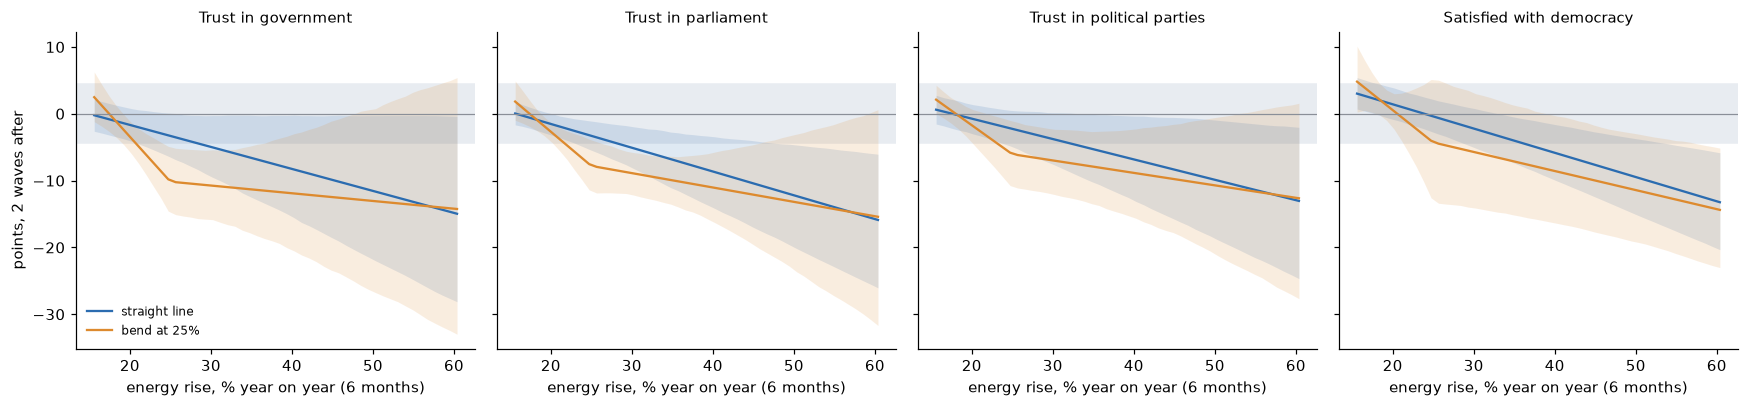

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
xs = np.linspace(THR, YOY_MAX, 50)
for ax, (o, label) in zip(axes, OUTCOMES.items()):
    for mdl, vecf, colr, lab in [(models[(o, 2)], lambda y_: reading_vec(models[(o, 2)], y_, EXAMPLE['months']), BLUE, 'straight line'),
                                 (models_sat[(o, 2)], lambda y_: reading_vec_sat(models_sat[(o, 2)], y_, EXAMPLE['months']), ORANGE, 'bend at 25%')]:
        th_, lo_, hi_ = wild_ci(mdl, np.array([vecf(y_).to_numpy() for y_ in xs]))
        ax.fill_between(xs, lo_, hi_, color=colr, alpha=0.15, lw=0); ax.plot(xs, th_, color=colr, label=lab)
    ax.axhspan(-NOISE, NOISE, color=LIGHT, zorder=0); ax.axhline(0, color=GREY, lw=0.8)
    ax.set_title(label, fontsize=10); ax.set_xlabel(f"energy rise, % year on year ({EXAMPLE['months']} months)")
axes[0].set_ylabel('points, 2 waves after'); axes[0].legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

**Reading this.** If the segment slopes agree across eras, the two eras were measuring different parts of one curve, not behaving differently. The fit comparison shows whether the data can *choose* between a straight line and a curve with a bend. If they cannot, the honest reading of a large surge is a **range covering both shapes**, and that is what is written for the dashboard.

### Which spells drive the result?

Each row re-estimates the intensity slope on a subset (main specification, with exposure controls); cells are the **effect per +1 point** of energy rise, 90% range. If a slope is real it should not need one group of countries or one period.

In [21]:
top6 = spells[(spells.iso3 != HELD_OUT) & ~spells.ongoing].groupby('iso3').yoy.max().nlargest(6).index.tolist()
SUBSETS = [('All spells (main)', lambda s: s),
           ('Spells before 2020 only', lambda s: s[s.date < np.datetime64('2020-01-01')]),
           ('2021 onward only', lambda s: s[s.date >= np.datetime64('2020-06-01')]),
           ('Without Estonia, Latvia, Lithuania', lambda s: s[~s.iso3.isin(['EST', 'LVA', 'LTU'])]),
           (f"Without the 6 strongest surges ({', '.join(top6)})", lambda s: s[~s.iso3.isin(top6)])]

def slope_stats(o, h, filt):
    s = filt(sample(o, h)); s = s[s.iso3 != HELD_OUT].reset_index(drop=True)
    if s.on.sum() < 8 or s.iso3.nunique() < 8:
        return None
    X = design(s, h=h); b, V, u, G = ols_cluster(s.dy, X, s.iso3.to_numpy())
    se, c = np.sqrt(V.loc['intensity', 'intensity']), t90(G - 1)
    return b['intensity'], b['intensity'] - c * se, b['intensity'] + c * se, int(s.on.sum())

def slope_cell(o, h, filt):
    r = slope_stats(o, h, filt)
    return 'too few spells' if r is None else f"{r[0]:+.2f} ({r[1]:+.2f} to {r[2]:+.2f})  n={r[3]}"

print('Effect per +1 point of energy rise, second wave after (h = 2):')
display(pd.DataFrame({OUTCOMES[o]: {name: slope_cell(o, 2, f) for name, f in SUBSETS} for o in OUTCOMES}))
for o in ['trust_gov', 'trust_parl']:
    print(f'{OUTCOMES[o]}: the same slope at every horizon:')
    display(pd.DataFrame({f'h = {h}': {name: slope_cell(o, h, f) for name, f in SUBSETS} for h in HORIZONS}))

Effect per +1 point of energy rise, second wave after (h = 2):


,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
All spells (main),-0.33 (-0.60 to -0.06) n=66,-0.36 (-0.55 to -0.16) n=66,-0.30 (-0.50 to -0.10) n=63,-0.36 (-0.54 to -0.18) n=51
Spells before 2020 only,-1.18 (-2.07 to -0.29) n=47,-1.12 (-1.65 to -0.59) n=47,-0.80 (-1.24 to -0.37) n=44,-1.02 (-2.25 to +0.21) n=32
2021 onward only,-0.13 (-0.50 to +0.25) n=19,-0.17 (-0.47 to +0.12) n=19,-0.20 (-0.47 to +0.06) n=19,-0.32 (-0.67 to +0.03) n=19
"Without Estonia, Latvia, Lithuania",-0.37 (-0.63 to -0.11) n=59,-0.35 (-0.54 to -0.16) n=59,-0.29 (-0.49 to -0.10) n=57,-0.42 (-0.58 to -0.26) n=46
"Without the 6 strongest surges (NLD, EST, BEL, GRC, LTU, LVA)",-0.70 (-1.27 to -0.12) n=47,-0.38 (-0.74 to -0.01) n=47,-0.41 (-0.75 to -0.07) n=45,-0.22 (-0.92 to +0.49) n=34


Trust in government: the same slope at every horizon:


,h = 1,h = 2,h = 3,h = 4
All spells (main),+0.03 (-0.14 to +0.20) n=66,-0.33 (-0.60 to -0.06) n=66,-0.08 (-0.37 to +0.22) n=66,-0.13 (-0.51 to +0.24) n=66
Spells before 2020 only,-0.60 (-0.94 to -0.26) n=47,-1.18 (-2.07 to -0.29) n=47,-1.53 (-2.71 to -0.35) n=47,-1.02 (-1.89 to -0.16) n=47
2021 onward only,+0.03 (-0.25 to +0.31) n=19,-0.13 (-0.50 to +0.25) n=19,+0.15 (-0.20 to +0.51) n=19,+0.22 (-0.37 to +0.81) n=19
"Without Estonia, Latvia, Lithuania",+0.01 (-0.16 to +0.18) n=59,-0.37 (-0.63 to -0.11) n=59,-0.11 (-0.38 to +0.17) n=59,-0.19 (-0.56 to +0.17) n=59
"Without the 6 strongest surges (NLD, EST, BEL, GRC, LTU, LVA)",-0.00 (-0.34 to +0.34) n=47,-0.70 (-1.27 to -0.12) n=47,-0.31 (-0.88 to +0.26) n=47,-0.13 (-0.53 to +0.27) n=47


Trust in parliament: the same slope at every horizon:


,h = 1,h = 2,h = 3,h = 4
All spells (main),+0.08 (-0.11 to +0.27) n=66,-0.36 (-0.55 to -0.16) n=66,-0.08 (-0.34 to +0.18) n=66,-0.13 (-0.48 to +0.21) n=66
Spells before 2020 only,-0.67 (-1.20 to -0.14) n=47,-1.12 (-1.65 to -0.59) n=47,-1.35 (-2.07 to -0.63) n=47,-0.83 (-1.48 to -0.19) n=47
2021 onward only,+0.08 (-0.20 to +0.36) n=19,-0.17 (-0.47 to +0.12) n=19,+0.01 (-0.25 to +0.28) n=19,+0.18 (-0.50 to +0.85) n=19
"Without Estonia, Latvia, Lithuania",+0.10 (-0.10 to +0.29) n=59,-0.35 (-0.54 to -0.16) n=59,-0.09 (-0.33 to +0.15) n=59,-0.16 (-0.50 to +0.18) n=59
"Without the 6 strongest surges (NLD, EST, BEL, GRC, LTU, LVA)",+0.24 (-0.11 to +0.58) n=47,-0.38 (-0.74 to -0.01) n=47,-0.12 (-0.66 to +0.41) n=47,+0.11 (-0.31 to +0.53) n=47


### The 2026 surge (a what-if until the autumn 2026 wave is published)

The energy series now runs to **October 2026**, and a new surge is under way. The Eurobarometer waves that would show its effect on trust (autumn 2026 and later) are not published yet, so nothing here is an observed outcome. It is the model's reading *if this surge behaves like past ones*. These spells are still running, so their length is not known; they are **not** used for estimation.

In [22]:
live = spells[spells.ongoing].copy()
live['latest'] = [float(energy[(energy.iso3 == r.iso3) & (energy.month == LAST_MONTH)].yoy.iloc[0]) for r in live.itertuples()]
print(f"{len(live)} countries are in a spell at {LAST_MONTH} ({len(live[live.latest > THR])} above the {THR:.1f}% threshold that month). Latest rate and spell so far:")
display(live.sort_values('latest', ascending=False).assign(start=lambda d: d.start.astype(str), end=lambda d: d.end.astype(str))[['iso3', 'start', 'months', 'yoy', 'latest']]
        .rename(columns={'months': 'months so far', 'yoy': 'mean rise so far', 'latest': f'rate in {LAST_MONTH}'}).round(1).set_index('iso3').T)
fr_live = live[live.iso3 == FOR].iloc[0] if (live.iso3 == FOR).any() else None
if fr_live is not None:
    rows = []
    for o in OUTCOMES:
        row = {'Outcome': OUTCOMES[o]}
        for m_ in (3, 6, 12):
            lin_ = reading_b(o, 2, float(fr_live.latest), m_); ben_ = reading_sat_b(o, 2, float(fr_live.latest), m_)
            row[f'surge lasts {m_} months'] = f"{(lin_[0] + ben_[0]) / 2:+.1f} ({min(lin_[1], ben_[1]):+.1f} to {max(lin_[2], ben_[2]):+.1f})"
        rows.append(row)
    print(f"France: a spell since {fr_live.start} ({fr_live.months} months so far, mean {fr_live.yoy:.1f}%, {fr_live.latest:.1f}% in {LAST_MONTH}). What-if reading at the latest rate, second wave after the start, range covering both dose-response shapes:")
    display(pd.DataFrame(rows).set_index('Outcome'))

19 countries are in a spell at 2026-10 (19 above the 15.6% threshold that month). Latest rate and spell so far:


iso3,BEL,LTU,ITA,LUX,GRC,CYP,FRA,BGR,ESP,HRV,SVN,PRT,IRL,FIN,EST,ROU,AUT,SWE,LVA
start,2026-04,2026-04,2026-08,2026-04,2026-09,2026-09,2026-05,2026-05,2026-08,2026-04,2026-09,2026-09,2026-10,2026-10,2026-09,2026-10,2026-10,2026-05,2026-09
months so far,7,7,3,7,2,2,6,6,3,7,2,2,1,1,2,1,1,6,2
mean rise so far,22.2,25.5,23.9,21.4,25.9,23.0,16.9,17.7,20.1,16.5,18.8,18.0,18.2,17.9,17.3,16.7,16.6,12.5,16.7
rate in 2026-10,39.4,32.6,31.9,26.6,26.4,25.1,23.9,22.1,21.1,20.0,19.3,19.1,18.2,17.9,17.8,16.7,16.6,16.3,16.2


France: a spell since 2026-05 (6 months so far, mean 16.9%, 23.9% in 2026-10). What-if reading at the latest rate, second wave after the start, range covering both dose-response shapes:


,surge lasts 3 months,surge lasts 6 months,surge lasts 12 months
Outcome,,,
Trust in government,-5.4 (-13.3 to +1.9),-5.8 (-12.8 to +0.2),-6.7 (-12.1 to -2.1)
Trust in parliament,-4.3 (-10.2 to +0.2),-4.8 (-10.0 to -0.9),-5.8 (-9.9 to -2.6)
Trust in political parties,-3.6 (-10.2 to +0.6),-3.5 (-9.6 to +0.6),-3.3 (-8.3 to +1.1)
Satisfied with democracy,-1.8 (-14.0 to +7.3),-1.6 (-10.4 to +4.4),-1.2 (-6.2 to +3.6)


## 10. Tables for the dashboard

Written to `outputs/model/` as `e_*`, in the layout of the specification's output table and of `s1_effects.csv`:

- `e_effects.csv`: one row per parameter × outcome × horizon: effect per unit, 90% range, number of spells, `estimated_without = FRA`. Parameters: `energy_shock` (base effect: a spell at the threshold, 1 month, average gas share), `energy_yoy` (per point of year-on-year rise above the threshold), `duration_months` (per month beyond the first) and `gas_share` (per point of gas share of supply, centred). `ci_low`/`ci_high` are wild-bootstrap ranges; `ci_low_t`/`ci_high_t` the cluster-robust t-ranges. Horizon 0 is the placebo.
- `e_reading_france.csv`: the example reading for France at each horizon with its bootstrap range, the same reading if the dose-response bends at 25% instead of being a straight line, the range covering both shapes, the half-width to add for **one** future episode, and a verdict. **This is the file to read the dashboard values from.**
- `e_grid.csv`: the example-style reading (line and bend, with bootstrap ranges) on a grid of energy rises and durations, for every outcome and horizon. **The dashboard reads this**, because it cannot add up separate parameter ranges correctly.
- `e_conformal.csv`: the single-episode half-widths and the back-test scores of both kinds of range.
- `e_exposure.csv`: each country's pre-shock exposure and the centring values, so the dashboard can apply France's own values.
- `e_france_check.csv`: France's 2021–23 spell, predicted without France, against what happened.
- `e_backtest.csv`: every leave-one-country-out prediction, with the "no change" error.
- `e_threshold.txt`: the rule that defines the shock, the threshold value, how the sliders and exposures are centred, and their limits.

In [23]:
PARAM = {'on': 'energy_shock', 'intensity': 'energy_yoy', 'months': 'duration_months', 'on_gas': 'gas_share'}
rows = []
for (o, h), mdl in models.items():
    c = c90(mdl); tci = term_cis(o, h)
    for t, name in PARAM.items():
        se = np.sqrt(mdl['V'].loc[t, t])
        rows.append({'shock': 'E', 'parameter': name, 'outcome': o, 'horizon': h, 'effect_per_unit': mdl['b'][t], 'ci_low': tci[t][1], 'ci_high': tci[t][2],
                     'ci_low_t': mdl['b'][t] - c * se, 'ci_high_t': mdl['b'][t] + c * se, 'n_events': mdl['n_events'], 'n_obs': mdl['n_obs'], 'estimated_without': HELD_OUT})
effects = pd.DataFrame(rows)
effects.round(4).to_csv(OUTDIR / 'e_effects.csv', index=False)
rd = []
for o in OUTCOMES:
    plac = reading_b(o, 0, EXAMPLE['yoy'], EXAMPLE['months'])
    for h in HORIZONS:
        m_, lo_, hi_ = reading_b(o, h, EXAMPLE['yoy'], EXAMPLE['months'])
        mt, lot, hit = reading(models[(o, h)], EXAMPLE['yoy'], EXAMPLE['months'])
        sm_, slo, shi = reading_sat_b(o, h, EXAMPLE['yoy'], EXAMPLE['months'])
        qh = float(conf[(conf.outcome == o) & (conf.horizon == h)].conformal_half_width.iloc[0])
        rd.append({'outcome': o, 'horizon': h, 'yoy': EXAMPLE['yoy'], 'months': EXAMPLE['months'], 'reading': m_, 'ci_low': lo_, 'ci_high': hi_,
                   'ci_low_t': lot, 'ci_high_t': hit, 'reading_bend': sm_, 'bend_low': slo, 'bend_high': shi,
                   'range_both_shapes_low': min(lo_, slo), 'range_both_shapes_high': max(hi_, shi),
                   'one_episode_half_width': qh, 'placebo_clean': bool(plac[1] <= 0 <= plac[2]),
                   'verdict': ('detectable change (range excludes zero)' if (lo_ > 0 or hi_ < 0) else 'no detectable change') + ('' if (plac[1] <= 0 <= plac[2]) else '; placebo not clean'),
                   'n_events': models[(o, h)]['n_events']})
pd.DataFrame(rd).round(3).to_csv(OUTDIR / 'e_reading_france.csv', index=False)
conf.round(3).to_csv(OUTDIR / 'e_conformal.csv', index=False)
exp_out = exposure.assign(centred_gas=lambda d: d.gas_share_pct - EXPO_MEAN['gas'], centred_russian=lambda d: d.russian_share_of_gas_imports_pct - EXPO_MEAN['rus'],
                          centred_frontline=lambda d: d.frontline - EXPO_MEAN['front'])
exp_out.round(2).rename_axis('iso3').to_csv(OUTDIR / 'e_exposure.csv')
for df_, name in [(france_check, 'e_france_check.csv'), (backtest, 'e_backtest.csv')]:
    df_.assign(date=pd.to_datetime(df_.date).dt.strftime('%Y-%m-%d')).round(3).to_csv(OUTDIR / name, index=False)
fx = exposure_terms(FOR)
(OUTDIR / 'e_threshold.txt').write_text(
    f"E energy-price shock. Rule: year-on-year rate of change of the HICP energy component (Eurostat prc_hicp_manr, NRG) above {THR:.2f}%, "
    f"the 90th percentile of EU-member country-months from Jan 2001, France excluded (specification: top 10%). A spell is a run of months above it, "
    f"gaps of up to {MERGE_GAP} months allowed. Sliders: energy rise {THR:.1f}% to {YOY_MAX:.0f}% year on year (mean over the spell), duration 1 to {MONTHS_MAX} months. "
    f"Reading = energy_shock + energy_yoy * (yoy - {THR:.2f}) + duration_months * (months - 1) + gas_share * ({GAS[FOR]:.1f} - {EXPO_MEAN['gas']:.2f}) (France's centred gas share: {fx['on_gas']:+.2f}). "
    f"Ranges: wild cluster bootstrap; add the half-width in e_conformal.csv to speak about one future episode. "
    f"Threshold fixed on the months to Dec 2025, before the 2026 surge; data run to {LAST_MONTH}. Spells still running at the end of the data are not used for estimation. "
    f"Estimated without France; waves from {START_WAVE:%b %Y}; baseline = mean of the two waves before the spell, after wave starts at least 30 days after it.\n", encoding='utf-8')
# Grid of readings for the dashboard: it looks up and interpolates, so the ranges stay joint (bootstrap) at any slider setting
YOY_GRID = sorted(set(list(range(16, int(YOY_MAX) + 1, 2)) + [int(YOY_MAX)]))
MONTH_GRID = [m_ for m_ in [1, 2, 3, 4, 6, 8, 10, 12, 15, 18, 21, 24, MONTHS_MAX] if m_ <= MONTHS_MAX]
pairs = [(y_, m_) for y_ in YOY_GRID for m_ in MONTH_GRID]
grid_rows = []
for o in OUTCOMES:
    for h in HORIZONS:
        lin = wild_ci(models[(o, h)], np.array([reading_vec(models[(o, h)], y_, m_).to_numpy() for y_, m_ in pairs]))
        ben = wild_ci(models_sat[(o, h)], np.array([reading_vec_sat(models_sat[(o, h)], y_, m_).to_numpy() for y_, m_ in pairs]))
        for i, (y_, m_) in enumerate(pairs):
            grid_rows.append({'outcome': o, 'horizon': h, 'yoy': y_, 'months': m_, 'line': lin[0][i], 'line_low': lin[1][i], 'line_high': lin[2][i],
                              'bend': ben[0][i], 'bend_low': ben[1][i], 'bend_high': ben[2][i], 'n_events': models[(o, h)]['n_events']})
pd.DataFrame(grid_rows).round(2).to_csv(OUTDIR / 'e_grid.csv', index=False)
print(f"e_grid.csv: {len(grid_rows)} rows ({len(YOY_GRID)} energy rises x {len(MONTH_GRID)} durations x {len(OUTCOMES)} outcomes x {len(HORIZONS)} horizons)")
spells.assign(start=spells.start.astype(str), end=spells.end.astype(str)).round(2).to_csv(OUTDIR / 'e_spells.csv', index=False)
live.assign(start=live.start.astype(str), end=live.end.astype(str)).round(2).to_csv(OUTDIR / 'e_current_surge.csv', index=False)
print('Wrote', ', '.join(p.name for p in sorted(OUTDIR.glob('e_*'))))

e_grid.csv: 4784 rows (23 energy rises x 13 durations x 4 outcomes x 4 horizons)
Wrote e_backtest.csv, e_conformal.csv, e_current_surge.csv, e_effects.csv, e_exposure.csv, e_france_check.csv, e_grid.csv, e_reading_france.csv, e_spells.csv, e_threshold.txt


## 11. What this says, and what it does not

In [24]:
lines = ['**What the panel says**', '']
n_sp = models[('trust_gov', 1)]['n_events']
lines.append(f"- **{n_sp} energy spells** in {models[('trust_gov', 1)]['events_countries']} EU countries since 2001 stand behind the estimates (France excluded). The threshold is {THR:.1f}% year on year.")
for o, label in OUTCOMES.items():
    cells_ = []
    for h in (1, 2, 3):
        m, lo, hi = reading_b(o, h, EXAMPLE['yoy'], EXAMPLE['months'])
        cells_.append(f"h={h} {m:+.1f} ({lo:+.1f} to {hi:+.1f}){' *' if (lo > 0 or hi < 0) else ''}")
    lines.append(f"- **{label}**, France, +{EXAMPLE['yoy']:.0f}% for {EXAMPLE['months']} months: " + '; '.join(cells_) + '.')
lines.append('  (* = range excludes zero; every other reading is *no detectable change*.)')
bad = rel[(rel.h == 1) & (rel['Placebo clean?'] != 'yes')]
lines.append('- **Placebo:** ' + ('clean for every outcome: trust was not already moving before the spells.' if bad.empty else
             'not clean for ' + ', '.join(bad.Outcome) + ': trust was already moving before the spells.'))
cmp_ = []
for o in ['trust_gov', 'trust_parl', 'swd']:
    a_, b_ = fit(o, 2, shock=NOEXPO)['b']['intensity'], models[(o, 2)]['b']['intensity']
    cmp_.append(f"{OUTCOMES[o].lower()} {a_:+.2f} to {b_:+.2f} ({1 - b_ / a_:.0%} smaller)")
lines.append("- **The gas-share control** changes the straight-line intensity slope at the second wave after, per point of energy rise, from " + '; '.join(cmp_) + ". It barely matters: the France reading is nearly the same with and without it (section 9).")
era_txt = []
for o in ['trust_gov', 'trust_parl']:
    mdl = era_models[(o, 2)]
    era_txt.append(f"{OUTCOMES[o].lower()} {mdl['b']['int_pre']:+.2f} before mid-2020 and {mdl['b']['int_post']:+.2f} from mid-2020")
within = {o: slope_stats(o, 2, lambda s: s[s.date >= np.datetime64('2020-06-01')]) for o in ['trust_gov', 'trust_parl']}
within_txt = '; '.join(f"{OUTCOMES[o].lower()} {r[0]:+.2f} ({r[1]:+.2f} to {r[2]:+.2f}, {'excludes' if (r[1] > 0 or r[2] < 0) else 'includes'} zero)" for o, r in within.items() if r)
lines.append("- **Two eras** (second wave after, per point): " + '; '.join(era_txt) + ". The earlier episodes are small and narrow in range, so their slope is steep but weakly identified; the segment table in section 9 suggests most of the gap is the shape of one curve (steep at low rises, flat above about 25%), not a different behaviour. Estimated on the 2021 onward spells alone, with their own base effect and exposure terms, the slope is " + within_txt + f": inside the 2021-23 surge itself the price-rise slope is not distinguishable from zero. This is not because of the exposure controls (the correlation between a spell's size and its country's exposure is only {sp21.yoy.corr(sp21.gas):+.2f}, {sp21.yoy.corr(sp21.rus):+.2f}, {sp21.yoy.corr(sp21.front):+.2f}); with {within['trust_gov'][3]} spells the slope is simply imprecise.")
dur_txt = []
for o in ['trust_gov', 'trust_parl']:
    dur_txt.append(f"{OUTCOMES[o].lower()} {models[(o, 3)]['b']['months']:+.2f} at h=3 and {models[(o, 4)]['b']['months']:+.2f} at h=4")
lines.append("- **Duration matters later than intensity:** per extra month of the spell, " + '; '.join(dur_txt) + ". The price-rise slope shows at the second wave after; the duration slope at the third and fourth, when a long spell is still running.")
w_t = {o: reading(models[(o, 2)], EXAMPLE['yoy'], EXAMPLE['months']) for o in OUTCOMES}; w_b = {o: reading_b(o, 2, EXAMPLE['yoy'], EXAMPLE['months']) for o in OUTCOMES}
lines.append("- **Bootstrap ranges** are " + ', '.join(f"{(w_b[o][2] - w_b[o][1]) / (w_t[o][2] - w_t[o][1]):.1f}x" for o in OUTCOMES) + " the width of the t-ranges at the second wave (government, parliament, parties, satisfaction): wider where the t-ranges were too narrow for this few countries.")
shape = {o: (reading_b(o, 2, EXAMPLE['yoy'], EXAMPLE['months']), reading_sat_b(o, 2, EXAMPLE['yoy'], EXAMPLE['months'])) for o in OUTCOMES}
lines.append("- **The shape of the dose-response changes the size of the reading.** At the example, second wave after, a straight line gives " + ', '.join(f"{OUTCOMES[o].lower()} {a_[0]:+.1f}" for o, (a_, b_) in shape.items()) + "; one curve that bends at 25% gives " + ', '.join(f"{b_[0]:+.1f}" for o, (a_, b_) in shape.items()) + ". The data cannot choose between them (section 9, fit table), and the era difference largely disappears inside each segment of the bent curve. The dashboard range should cover both.")
lines.append(f"- **Forward in time:** estimated on spells before mid-2020 only, the model beats 'all countries alike' in {int(fwd.beats.sum())} of {len(fwd)} cells when asked about 2021-23. It gets the *pattern* roughly right (median correlation {fwd['corr(pred, actual)'].median():.2f}) but the *size* wrong: actual effects are about {fwd['actual per predicted'].median():.2f} times the predicted ones. The earlier, smaller episodes say who is hit harder, not by how much at a large surge.")
lines.append(f"- **Ex-ante version:** a model using only the rise over the first three months (no duration, so usable as a forecast) is preferred by BIC in {int((exa[bic_col] < 0).sum())} of {len(exa)} cells, including {int((exa[exa.h <= 2][bic_col] < 0).sum())} of {int((exa.h <= 2).sum())} at the first two waves. Duration is needed mainly for trust in government and parliament at the third and fourth waves. A dashboard on an ex-ante input is feasible but needs its own slider and limits.")
lines.append(f"- **2026:** the energy series now runs to {LAST_MONTH}. {len(live)} countries are in a spell, all above the {THR:.1f}% threshold that month" + (f"; France since {fr_live.start}, {fr_live.latest:.1f}% in {LAST_MONTH}" if fr_live is not None else '') + ". No Eurobarometer wave after the surge is published, so this is a what-if (section 10), not an observed effect.")
gain = (1 - skill['MAE model'] / skill['MAE "no change"'])
lines.append(f"- **Back-test:** coverage of the model's own single-episode ranges {backtest.inside.mean():.0%} of {len(backtest)} predictions (target about 90%); the **conformal** ranges reach {conf['conformal coverage'].mean():.0%}, at an average width of {conf['conformal width'].mean():.0f} points (add that half-width around a reading to speak about one future episode). The model beats a prediction of *no change* in {int(skill['model beats no-change'].sum())} of {len(skill)} outcome-horizon cells, with an error {gain.median():.0%} lower at the median cell ({gain.max():.0%} lower in the best cell; {'higher' if gain.min() < 0 else 'lower'} by {abs(gain.min()):.0%} in the worst); the correlation between predicted and actual is {skill['corr(pred, actual)'].min():.2f} to {skill['corr(pred, actual)'].max():.2f}.")
fr_ = france_check[france_check.horizon == 1]
if len(fr_):
    g2 = france_check[(france_check.outcome == 'trust_gov') & (france_check.horizon == 2)]
    lines.append(f"- **France 2021–23, out of sample:** {int(france_check.inside.sum())} of {len(france_check)} readings fall inside the model's range and {int(france_check.inside_conformal.sum())} of {len(france_check)} inside the conformal range, but both are wide" + (f"; at h = 2 trust in government moved {g2.actual.iloc[0]:+.1f} beyond the rest of Europe against a predicted {g2.predicted.iloc[0]:+.1f}." if len(g2) else '.'))
display(Markdown('\n'.join(lines)))

**What the panel says**

- **66 energy spells** in 25 EU countries since 2001 stand behind the estimates (France excluded). The threshold is 15.6% year on year.
- **Trust in government**, France, +35% for 6 months: h=1 -0.2 (-3.7 to +3.3); h=2 -6.6 (-12.5 to -0.2) *; h=3 -2.4 (-7.9 to +3.1).
- **Trust in parliament**, France, +35% for 6 months: h=1 +0.5 (-3.3 to +4.1); h=2 -6.9 (-11.2 to -2.8) *; h=3 -3.0 (-7.4 to +1.3).
- **Trust in political parties**, France, +35% for 6 months: h=1 -0.7 (-2.3 to +0.8); h=2 -5.3 (-10.3 to -0.1) *; h=3 -3.0 (-7.2 to +1.2).
- **Satisfied with democracy**, France, +35% for 6 months: h=1 +0.6 (-3.1 to +4.5); h=2 -4.0 (-7.4 to -0.5) *; h=3 +2.8 (-0.8 to +6.5).
  (* = range excludes zero; every other reading is *no detectable change*.)
- **Placebo:** clean for every outcome: trust was not already moving before the spells.
- **The gas-share control** changes the straight-line intensity slope at the second wave after, per point of energy rise, from trust in government -0.34 to -0.33 (4% smaller); trust in parliament -0.37 to -0.36 (4% smaller); satisfied with democracy -0.38 to -0.36 (5% smaller). It barely matters: the France reading is nearly the same with and without it (section 9).
- **Two eras** (second wave after, per point): trust in government -1.25 before mid-2020 and -0.32 from mid-2020; trust in parliament -1.12 before mid-2020 and -0.37 from mid-2020. The earlier episodes are small and narrow in range, so their slope is steep but weakly identified; the segment table in section 9 suggests most of the gap is the shape of one curve (steep at low rises, flat above about 25%), not a different behaviour. Estimated on the 2021 onward spells alone, with their own base effect and exposure terms, the slope is trust in government -0.13 (-0.50 to +0.25, includes zero); trust in parliament -0.17 (-0.47 to +0.12, includes zero): inside the 2021-23 surge itself the price-rise slope is not distinguishable from zero. This is not because of the exposure controls (the correlation between a spell's size and its country's exposure is only +0.13, -0.02, -0.05); with 19 spells the slope is simply imprecise.
- **Duration matters later than intensity:** per extra month of the spell, trust in government -0.65 at h=3 and -0.65 at h=4; trust in parliament -0.67 at h=3 and -0.78 at h=4. The price-rise slope shows at the second wave after; the duration slope at the third and fourth, when a long spell is still running.
- **Bootstrap ranges** are 1.2x, 1.2x, 1.3x, 0.9x the width of the t-ranges at the second wave (government, parliament, parties, satisfaction): wider where the t-ranges were too narrow for this few countries.
- **The shape of the dose-response changes the size of the reading.** At the example, second wave after, a straight line gives trust in government -6.6, trust in parliament -6.9, trust in political parties -5.3, satisfied with democracy -4.0; one curve that bends at 25% gives -11.3, -10.0, -7.9, -7.1. The data cannot choose between them (section 9, fit table), and the era difference largely disappears inside each segment of the bent curve. The dashboard range should cover both.
- **Forward in time:** estimated on spells before mid-2020 only, the model beats 'all countries alike' in 1 of 16 cells when asked about 2021-23. It gets the *pattern* roughly right (median correlation 0.43) but the *size* wrong: actual effects are about 0.22 times the predicted ones. The earlier, smaller episodes say who is hit harder, not by how much at a large surge.
- **Ex-ante version:** a model using only the rise over the first three months (no duration, so usable as a forecast) is preferred by BIC in 12 of 16 cells, including 8 of 8 at the first two waves. Duration is needed mainly for trust in government and parliament at the third and fourth waves. A dashboard on an ex-ante input is feasible but needs its own slider and limits.
- **2026:** the energy series now runs to 2026-10. 19 countries are in a spell, all above the 15.6% threshold that month; France since 2026-05, 23.9% in 2026-10. No Eurobarometer wave after the surge is published, so this is a what-if (section 10), not an observed effect.
- **Back-test:** coverage of the model's own single-episode ranges 82% of 984 predictions (target about 90%); the **conformal** ranges reach 90%, at an average width of 29 points (add that half-width around a reading to speak about one future episode). The model beats a prediction of *no change* in 11 of 16 outcome-horizon cells, with an error 7% lower at the median cell (20% lower in the best cell; higher by 8% in the worst); the correlation between predicted and actual is -0.26 to 0.50.
- **France 2021–23, out of sample:** 16 of 16 readings fall inside the model's range and 16 of 16 inside the conformal range, but both are wide; at h = 2 trust in government moved -11.9 beyond the rest of Europe against a predicted -5.2.

**What it cannot show**

- **Not a cause.** Wave effects remove Europe-wide moves and country effects a country's usual drift, and the exposure controls remove the part tied to gas dependence and proximity to the war, but an energy surge and a fall in trust can still share causes the model does not see: supply worries, overall inflation (not controlled after the shock, since the specification measures E's *total* effect) and, in France, the price cap.
- **Hit together.** In 2021–22 almost every country is above the threshold at once, so the base effect rests on the earlier, smaller episodes, and the slopes on differences between countries. With about 60 usable spells, every extra control costs precision, which is why the main model has one exposure term.
- **Exposure data are limited.** Gas share of supply is the only exposure in the main model; the Russian share (understated for countries that buy through neighbours, such as Austria and Ireland) and the front-line indicator are checks only. The UK has no exposure data (its spells are dropped).
- **Duration is not known in advance.** A spell's length is known only when it ends, so using it to predict at the start of a surge uses information from the future. The dashboard slider asks the user for it, which is a *what if*, not a forecast.
- **Timing is still coarse.** Eurobarometer asks twice a year; the 30-day rule removes the worst cases but "h = 1" can still be up to six months after the spell starts.
- **Pass-through.** The slider is the energy rise in the HICP, which includes any price cap and tax change. France's cap kept its energy inflation below its neighbours', so a French reading from other countries' spells may overstate the shock France actually felt.
- **Not yet in:** radical vote share at the next election, months to the next scheduled election, a combined energy-and-financial scenario (needs its own interaction term; adding the two effects would overstate the damage), and the effect of the 2026 surge, whose Eurobarometer waves are not published yet (the energy series itself runs to October 2026).